# 2η Εργασία: Νευρωνικά Δίκτυα για Ταξινόμηση Εικόνων
## WikiArt – Ταξινόμηση Καλλιτεχνικών Κινημάτων


In [1]:
# ============================================================
# Imports and reproducibility seeds
# ============================================================
import numpy as np
import os
import random
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import time
import copy

# --- Reproducibility ---
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


## 0. Δεδομένα

### 0.1 Φόρτωση και Προετοιμασία

In [2]:
# ============================================================
# Section 0.1 - Load the WikiArt dataset from .npz file
# ============================================================

DATA_PATH = '/content/wikiart_hw2.npz'

# Unzip the dataset file if it's not already extracted

if not os.path.exists(DATA_PATH):
    print("Unzipping wikiart_hw2.npz.zip...")
    !unzip /content/wikiart_hw2.npz.zip -d /content/

data = np.load(DATA_PATH, allow_pickle=True)

X_raw = data['X']
y_raw = data['y']
class_names = data['class_names']

print(f"X shape: {X_raw.shape}, dtype: {X_raw.dtype}")
print(f"y shape: {y_raw.shape}, dtype: {y_raw.dtype}")
print(f"Class names: {class_names}")
print(f"Samples per class: { {name: int((y_raw == i).sum()) for i, name in enumerate(class_names)} }")
print(f"Pixel value range: [{X_raw.min()}, {X_raw.max()}]")

Unzipping wikiart_hw2.npz.zip...
Archive:  /content/wikiart_hw2.npz.zip
  inflating: /content/wikiart_hw2.npz  
  inflating: /content/__MACOSX/._wikiart_hw2.npz  
X shape: (5400, 32, 32, 3), dtype: uint8
y shape: (5400,), dtype: int64
Class names: ['Baroque' 'Impressionism' 'Cubism' 'Abstract_Expressionism']
Samples per class: {np.str_('Baroque'): 1350, np.str_('Impressionism'): 1350, np.str_('Cubism'): 1350, np.str_('Abstract_Expressionism'): 1350}
Pixel value range: [0, 255]


In [3]:
# ============================================================
# Preprocessing: normalize to [0,1], convert to channels-first
# PyTorch format: [N, C, H, W]
# ============================================================

# Normalize pixel values from [0,255] to [0,1] (float32)
X = X_raw.astype(np.float32) / 255.0

# Convert from channels-last (N, H, W, C) to channels-first (N, C, H, W)
# using transpose (axis reordering): 0=N stays, 3=C moves to 1, 1=H to 2, 2=W to 3
X = X.transpose(0, 3, 1, 2)
y = y_raw.astype(np.int64)

print(f"After preprocessing - X shape: {X.shape}, dtype: {X.dtype}")
print(f"Pixel value range after normalization: [{X.min():.4f}, {X.max():.4f}]")

# ============================================================
# Train / Val / Test split
# Target: 800 train, 200 val, 350 test per class
#         = 3200 / 800 / 1400 total
# Strategy: two sequential stratified splits
#   Step 1: split (5400) → temp_train (4000) + test (1400)
#   Step 2: split temp_train (4000) → train (3200) + val (800)
# ============================================================

# Step 1: separate out the test set (1400 samples = 350 per class)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=1400,
    stratify=y,
    random_state=SEED
)

# Step 2: separate val from remaining (800 samples = 200 per class)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=800,
    stratify=y_temp,
    random_state=SEED
)

print(f"\nSplit sizes:")
print(f"  Train : {X_train.shape[0]} samples")
print(f"  Val   : {X_val.shape[0]} samples")
print(f"  Test  : {X_test.shape[0]} samples")

print(f"\nSamples per class in each split:")
for split_name, y_split in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    counts = {class_names[i]: int((y_split == i).sum()) for i in range(len(class_names))}
    print(f"  {split_name}: {counts}")

After preprocessing - X shape: (5400, 3, 32, 32), dtype: float32
Pixel value range after normalization: [0.0000, 1.0000]

Split sizes:
  Train : 3200 samples
  Val   : 800 samples
  Test  : 1400 samples

Samples per class in each split:
  Train: {np.str_('Baroque'): 800, np.str_('Impressionism'): 800, np.str_('Cubism'): 800, np.str_('Abstract_Expressionism'): 800}
  Val: {np.str_('Baroque'): 200, np.str_('Impressionism'): 200, np.str_('Cubism'): 200, np.str_('Abstract_Expressionism'): 200}
  Test: {np.str_('Baroque'): 350, np.str_('Impressionism'): 350, np.str_('Cubism'): 350, np.str_('Abstract_Expressionism'): 350}


In [4]:
# ============================================================
# Convert numpy arrays to PyTorch tensors and create DataLoaders
# ============================================================

BATCH_SIZE = 16

# Convert to tensors
X_train_t = torch.tensor(X_train)
X_val_t   = torch.tensor(X_val)
X_test_t  = torch.tensor(X_test)
y_train_t = torch.tensor(y_train)
y_val_t   = torch.tensor(y_val)
y_test_t  = torch.tensor(y_test)

# Create TensorDatasets
train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset   = TensorDataset(X_val_t,   y_val_t)
test_dataset  = TensorDataset(X_test_t,  y_test_t)

# Create DataLoaders
# shuffle=True for train/val (randomizes batch order each epoch)
# shuffle=False for test (deterministic evaluation)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          worker_init_fn=lambda _: np.random.seed(SEED))
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=True,
                          worker_init_fn=lambda _: np.random.seed(SEED))
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

print(f"Batch size: {BATCH_SIZE}")
print(f"Train batches: {len(train_loader)}")
print(f"Val batches  : {len(val_loader)}")
print(f"Test batches : {len(test_loader)}")

# Verify a batch
xb, yb = next(iter(train_loader))
print(f"\nSample batch - X: {xb.shape}, y: {yb.shape}")
print(f"X dtype: {xb.dtype}, y dtype: {yb.dtype}")

Batch size: 16
Train batches: 200
Val batches  : 50
Test batches : 88

Sample batch - X: torch.Size([16, 3, 32, 32]), y: torch.Size([16])
X dtype: torch.float32, y dtype: torch.int64


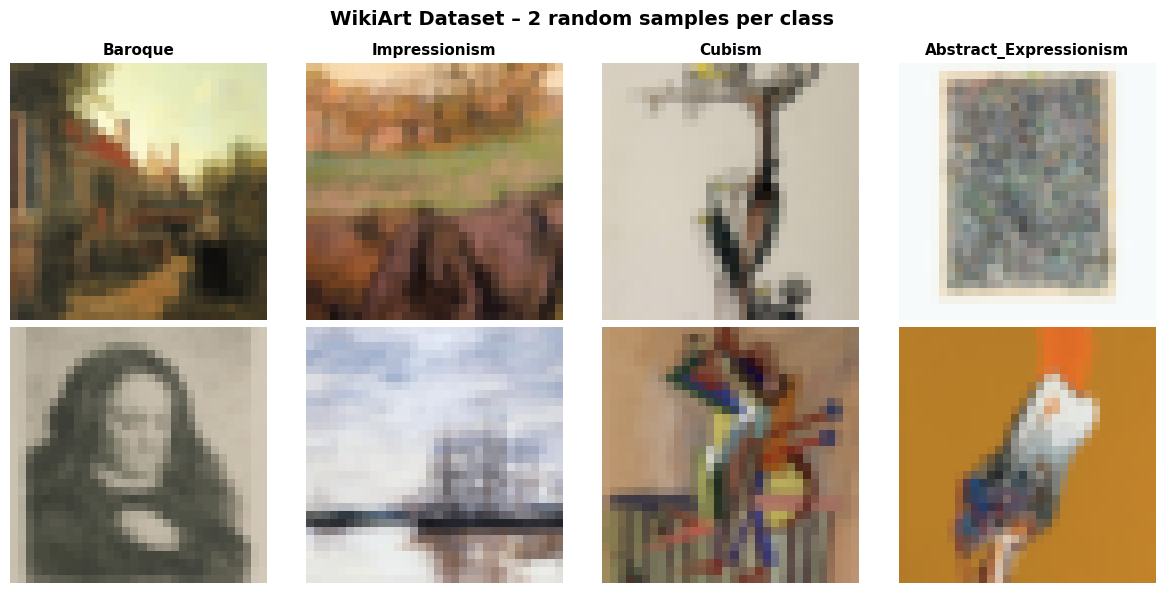

Sample visualization saved.


In [5]:
# ============================================================
# Visualize 2 random images per class (2 rows x 4 columns)
# Rows = examples, Columns = classes
# ============================================================

np.random.seed(SEED)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
fig.suptitle("WikiArt Dataset – 2 random samples per class", fontsize=14, fontweight='bold')

for col, (cls_idx, cls_name) in enumerate(zip(range(len(class_names)), class_names)):
    # Find indices belonging to this class in the training set
    class_indices = np.where(y_train == cls_idx)[0]
    sampled = np.random.choice(class_indices, size=2, replace=False)

    for row, idx in enumerate(sampled):
        ax = axes[row, col]
        # Convert from channels-first (C, H, W) back to (H, W, C) for display
        img = X_train[idx].transpose(1, 2, 0)
        ax.imshow(img)
        ax.axis('off')
        if row == 0:
            ax.set_title(cls_name, fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('section0_samples.png', dpi=150, bbox_inches='tight')
plt.show()
print("Sample visualization saved.")

## Q0.1 (3 μον.)

Από την οπτικοποίηση, τα τέσσερα κινήματα παρουσιάζουν σαφείς οπτικές διαφορές στα εξής χαρακτηριστικά:

- **Χρωματική παλέτα:** Το Μπαρόκ έχει σκούρες, γήινες αποχρώσεις με έντονες αντιθέσεις φωτεινού-σκούρου. Ο Ιμπρεσιονισμός χρησιμοποιεί παστέλ, φωτεινές αποχρώσεις . Ο Κυβισμός είναι κυρίως ουδέτερος. Ο Αφαιρετικός Εξπρεσιονισμός έχει μεγάλα πεδία χρώματος χωρίς σαφή μορφή.

- **Υφή και πινελιές:** Ιμπρεσιονισμός: ορατές, χαλαρές πινελιές. Κυβισμός: γεωμετρικές γραμμές, θραυσματική δομή. Αφαιρετικός Εξπρεσιονισμός: χειρονομιακές, άναρχες πινελιές. Μπαρόκ: λεπτή υφή, ρεαλιστική απόδοση.

- **Παρουσία θέματος:** Μπαρόκ και Ιμπρεσιονισμός έχουν αναγνωρίσιμα θέματα (πρόσωπα, τοπία), ενώ Κυβισμός και Αφαιρετικός Εξπρεσιονισμός δύσκολα αναγνωρίσιμα σε 32×32.

**Πιο εύκολα μπερδεμένα ζεύγη:** Κυβισμός–Αφαιρετικός Εξπρεσιονισμός, λόγω κοινής αφηρημένης δομής και ουδέτερης παλέτας. Επίσης πιθανώς Μπαρόκ–Ιμπρεσιονισμός, όταν η εικόνα είναι αρκετά σκοτεινή ή ο φωτισμός δεν είναι σαφής.

**Δυσκολότερο κίνημα για άνθρωπο στα 32×32:** Ο Αφαιρετικός Εξπρεσιονισμός, γιατί στερείται αναγνωρίσιμης μορφής και εξαρτάται από λεπτομέρειες υφής/χειρονομίας που χάνονται στο downsampling. Δευτερευόντως ο Ιμπρεσιονισμός, καθώς οι χαλαρές πινελιές του αλλοιώνονται σημαντικά στα 32×32.

## 1. Feedforward Neural Network σε Raw Pixels

### 1.1 Αρχιτεκτονική και Εκπαίδευση

In [6]:
# ============================================================
# Section 1.1 - Feedforward Neural Network (FFN / MLP)
# Input: flattened image = 32*32*3 = 3072 values
# Architecture: 3072 → 128 → 32 → 4
# Activations: ReLU between layers, NO activation after last layer
# ============================================================

class FFN(nn.Module):
    def __init__(self):
        super(FFN, self).__init__()
        self.network = nn.Sequential(
            nn.Flatten(),               # (N, 3, 32, 32) → (N, 3072)
            nn.Linear(3072, 128),       # first linear layer
            nn.ReLU(),                  # non-linearity
            nn.Linear(128, 32),         # second linear layer
            nn.ReLU(),                  # non-linearity
            nn.Linear(32, 4)            # output layer: 4 classes, no activation
        )

    def forward(self, x):
        return self.network(x)

# Instantiate and inspect
model_ffn = FFN()
print(model_ffn)

total_params = sum(p.numel() for p in model_ffn.parameters())
trainable_params = sum(p.numel() for p in model_ffn.parameters() if p.requires_grad)
print(f"\nTotal parameters    : {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

FFN(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=4, bias=True)
  )
)

Total parameters    : 397,604
Trainable parameters: 397,604


In [7]:
# ============================================================
# Training and evaluation helper functions
# ============================================================

def train_one_epoch(model, loader, optimizer, criterion, device):
    """
    Runs one full epoch of training.
    Returns average training loss for the epoch.
    """
    model.train()
    total_loss = 0.0
    n_samples = 0

    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()           # clear previous gradients
        logits = model(X_batch)         # forward pass
        loss = criterion(logits, y_batch)  # compute loss
        loss.backward()                 # backpropagation
        optimizer.step()                # update parameters

        total_loss += loss.item() * X_batch.size(0)
        n_samples  += X_batch.size(0)

    return total_loss / n_samples


def evaluate(model, loader, criterion, device):
    """
    Evaluates the model on a given DataLoader (no gradient updates).
    Returns: avg_loss, accuracy, f1_macro, confusion_matrix
    """
    model.eval()
    total_loss = 0.0
    all_preds  = []
    all_labels = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            logits = model(X_batch)
            loss   = criterion(logits, y_batch)

            total_loss += loss.item() * X_batch.size(0)

            preds = logits.argmax(dim=1)
            all_preds.append(preds.cpu().numpy())
            all_labels.append(y_batch.cpu().numpy())

    all_preds  = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)

    avg_loss = total_loss / len(loader.dataset)
    accuracy = (all_preds == all_labels).mean()
    f1       = f1_score(all_labels, all_preds, average='macro')
    cm       = confusion_matrix(all_labels, all_preds)

    return avg_loss, accuracy, f1, cm


print("Helper functions defined: train_one_epoch(), evaluate()")

Helper functions defined: train_one_epoch(), evaluate()


In [8]:
# ============================================================
# Section 1.1 - Training loop: train on GPU and CPU, record times
# Hyperparameters: Adam lr=0.001, CrossEntropyLoss, 30 epochs
# Model selection: best val F1 macro
# ============================================================

NUM_EPOCHS = 30
LR = 0.001
criterion = nn.CrossEntropyLoss()

def run_training(device_name, train_loader, val_loader, seed=SEED):
    """
    Full training loop for the FFN on a given device.
    Returns: history dict, best model state_dict, best epoch index
    """
    # Re-seed for reproducibility across device runs
    torch.manual_seed(seed)
    np.random.seed(seed)

    device = torch.device(device_name)
    model  = FFN().to(device)
    optimizer = optim.Adam(model.parameters(), lr=LR)

    history = {
        'train_loss': [],
        'val_loss':   [],
        'val_acc':    [],
        'val_f1':     []
    }

    best_val_f1    = -1.0
    best_state     = None
    best_epoch     = 0

    print(f"\n{'='*55}")
    print(f"Training FFN on: {device_name.upper()}")
    print(f"{'='*55}")

    start_time = time.time()

    for epoch in range(NUM_EPOCHS):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
        val_loss, val_acc, val_f1, _ = evaluate(model, val_loader, criterion, device)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['val_f1'].append(val_f1)

        # Save best model based on validation F1 macro
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state  = copy.deepcopy(model.state_dict())
            best_epoch  = epoch + 1  # 1-indexed

        print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
              f"Train Loss: {train_loss:.4f} | "
              f"Val Loss: {val_loss:.4f} | "
              f"Val Acc: {val_acc:.4f} | "
              f"Val F1: {val_f1:.4f}"
              + (" ← best" if (epoch + 1) == best_epoch else ""))

    elapsed = time.time() - start_time
    print(f"\nTraining time on {device_name.upper()}: {elapsed:.2f}s")
    print(f"Best model selected at epoch {best_epoch} (Val F1 = {best_val_f1:.4f})")

    return history, best_state, best_epoch, elapsed


# --- Train on GPU ---
if torch.cuda.is_available():
    history_gpu, best_state_gpu, best_epoch_gpu, time_gpu = run_training(
        'cuda', train_loader, val_loader
    )
else:
    print("WARNING: CUDA not available. Skipping GPU training.")
    history_gpu, best_state_gpu, best_epoch_gpu, time_gpu = None, None, None, None

# --- Train on CPU ---
history_cpu, best_state_cpu, best_epoch_cpu, time_cpu = run_training(
    'cpu', train_loader, val_loader
)

# --- Report timing comparison ---
print(f"\n{'='*40}")
print(f"Timing Summary:")
if time_gpu:
    print(f"  GPU training time: {time_gpu:.2f}s")
print(f"  CPU training time: {time_cpu:.2f}s")
if time_gpu:
    print(f"  GPU speedup: {time_cpu/time_gpu:.1f}x faster than CPU")


Training FFN on: CUDA
Epoch 01/30 | Train Loss: 1.3785 | Val Loss: 1.3477 | Val Acc: 0.3412 | Val F1: 0.2504 ← best
Epoch 02/30 | Train Loss: 1.3155 | Val Loss: 1.2876 | Val Acc: 0.4100 | Val F1: 0.3652 ← best
Epoch 03/30 | Train Loss: 1.2744 | Val Loss: 1.2587 | Val Acc: 0.4338 | Val F1: 0.4274 ← best
Epoch 04/30 | Train Loss: 1.2499 | Val Loss: 1.2604 | Val Acc: 0.4300 | Val F1: 0.3852
Epoch 05/30 | Train Loss: 1.2297 | Val Loss: 1.2484 | Val Acc: 0.4412 | Val F1: 0.3926
Epoch 06/30 | Train Loss: 1.2142 | Val Loss: 1.2309 | Val Acc: 0.4412 | Val F1: 0.4446 ← best
Epoch 07/30 | Train Loss: 1.1888 | Val Loss: 1.2156 | Val Acc: 0.4313 | Val F1: 0.4030
Epoch 08/30 | Train Loss: 1.1803 | Val Loss: 1.2041 | Val Acc: 0.4775 | Val F1: 0.4635 ← best
Epoch 09/30 | Train Loss: 1.1658 | Val Loss: 1.2633 | Val Acc: 0.4637 | Val F1: 0.4269
Epoch 10/30 | Train Loss: 1.1476 | Val Loss: 1.1994 | Val Acc: 0.4575 | Val F1: 0.4259
Epoch 11/30 | Train Loss: 1.1464 | Val Loss: 1.1923 | Val Acc: 0.4537 | 

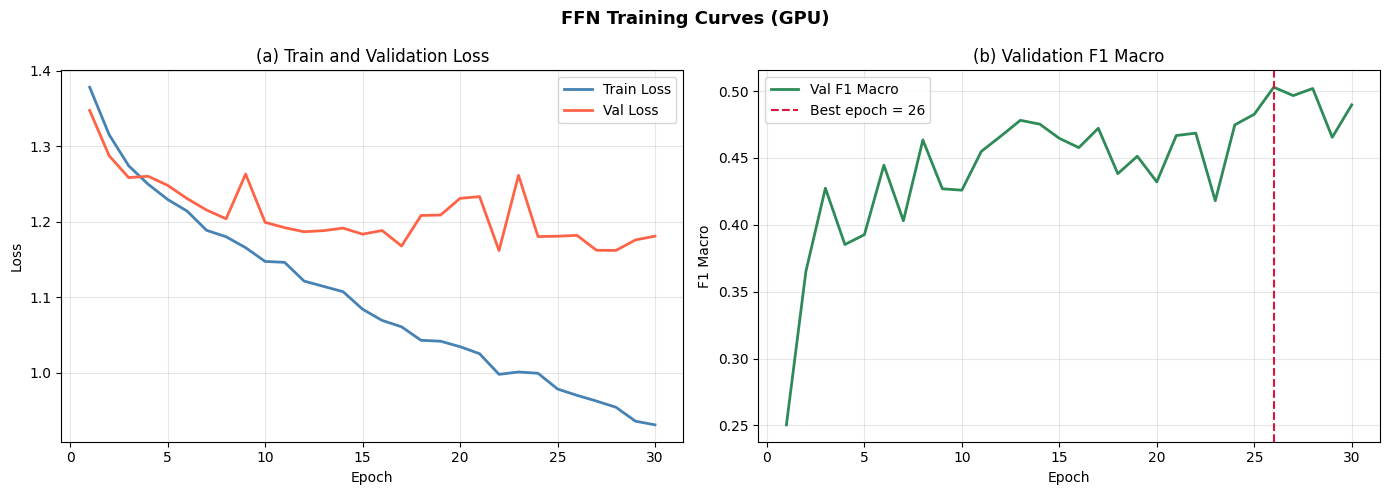

Training curves saved. Best model epoch: 26


In [9]:
# ============================================================
# Plot (a) train/val loss curves and (b) val F1 curve
# Using GPU history as primary
# ============================================================

history = history_gpu if history_gpu is not None else history_cpu
best_epoch = best_epoch_gpu if best_epoch_gpu is not None else best_epoch_cpu

epochs_range = range(1, NUM_EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("FFN Training Curves (GPU)", fontsize=13, fontweight='bold')

# --- Plot (a): Train vs Validation Loss ---
ax = axes[0]
ax.plot(epochs_range, history['train_loss'], label='Train Loss', color='steelblue', linewidth=2)
ax.plot(epochs_range, history['val_loss'],   label='Val Loss',   color='tomato',    linewidth=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('(a) Train and Validation Loss')
ax.legend()
ax.grid(True, alpha=0.3)

# --- Plot (b): Validation F1 with vertical line at best epoch ---
ax = axes[1]
ax.plot(epochs_range, history['val_f1'], label='Val F1 Macro', color='seagreen', linewidth=2)
ax.axvline(x=best_epoch, color='crimson', linestyle='--', linewidth=1.5,
           label=f'Best epoch = {best_epoch}')
ax.set_xlabel('Epoch')
ax.set_ylabel('F1 Macro')
ax.set_title('(b) Validation F1 Macro')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('section1_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Training curves saved. Best model epoch: {best_epoch}")

In [10]:
# ============================================================
# Section 1.1 - Load best model state and evaluate on test set
# ============================================================

# Use GPU best model if available, otherwise CPU
best_state  = best_state_gpu  if best_state_gpu  is not None else best_state_cpu
best_epoch  = best_epoch_gpu  if best_epoch_gpu  is not None else best_epoch_cpu
eval_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Load best weights into a fresh model instance
best_model_ffn = FFN().to(eval_device)
best_model_ffn.load_state_dict(best_state)

# Evaluate on val and test sets
val_loss,  val_acc,  val_f1,  val_cm  = evaluate(best_model_ffn, val_loader,  criterion, eval_device)
test_loss, test_acc, test_f1, test_cm = evaluate(best_model_ffn, test_loader, criterion, eval_device)

print("=" * 50)
print(f"Best Model (epoch {best_epoch}) — Validation Set:")
print(f"  Loss    : {val_loss:.4f}")
print(f"  Accuracy: {val_acc:.4f}")
print(f"  F1 Macro: {val_f1:.4f}")
print()
print(f"Best Model (epoch {best_epoch}) — Test Set:")
print(f"  Loss    : {test_loss:.4f}")
print(f"  Accuracy: {test_acc:.4f}")
print(f"  F1 Macro: {test_f1:.4f}")
print("=" * 50)

Best Model (epoch 26) — Validation Set:
  Loss    : 1.1821
  Accuracy: 0.5038
  F1 Macro: 0.5029

Best Model (epoch 26) — Test Set:
  Loss    : 1.1694
  Accuracy: 0.5057
  F1 Macro: 0.5044


## Q1.1 (5 μον.)

**Overfitting/Underfitting:** Παρατηρείται ήπιο overfitting. Το train loss μειώνεται σταθερά (1.38 σε ~ 0.93 στις 30 εποχές), ενώ το val loss σταθεροποιείται σε plateau (~ 1.18–1.25) με έντονη μεταβλητότητα από τις πρώτες 10 εποχές. Δεν υπάρχει σαφής αύξηση του val loss, αλλά η αυξανόμενη απόκλιση train–val (~ 0.35 στο τέλος) υποδεικνύει εξειδίκευση στα training data.

**Επιλογή best model:** Η καμπύλη val F1 έχει έντονες διακυμάνσεις λόγω μικρού val set (800 δείγματα). Το peak εντοπίζεται στην **εποχή 26** (Val F1 = 0.5029). Αν χρησιμοποιούσαμε ως κριτήριο το train loss, θα επιλεγόταν η **εποχή 30** — το πιο overfitted σημείο.

**Κρισιμότητα validation set:**  Το validation set μας δίνει μια αμερόληπτη εκτίμηση του generalization error σε κάθε εποχή, επιτρέποντας να επιλέξουμε το μοντέλο που ελαχιστοποιεί αυτό το σφάλμα (hold-out method). Χρήση train loss ως κριτήριο θα οδηγούσε πάντα στην τελευταία εποχή, ανεξαρτήτως overfitting.

**GPU speedup:** GPU: 14.22s, CPU: 50.46s με speedup **3.5x**. Αυτό είναι χαμηλότερο speedup σε σχέση με CNN, και είναι **αναμενόμενο** για δίκτυο αυτού του μεγέθους: το FFN με 397K παραμέτρους αποτελείται μόνο από matrix multiplications σχετικά μικρού μεγέθους, οπότε ο παραλληλισμός του GPU δεν αξιοποιείται πλήρως. Τα μεγαλύτερα batch operations του CNN εκμεταλλεύονται καλύτερα τη GPU αρχιτεκτονική.

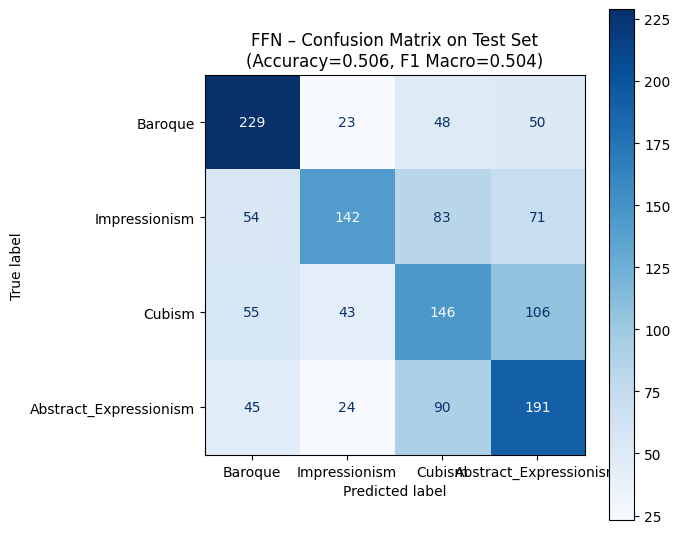

Confusion matrix saved.


In [11]:
# ============================================================
# Q1.2 - Confusion matrix on the test set
# ============================================================

fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=test_cm,
                              display_labels=class_names)
disp.plot(ax=ax, colorbar=True, cmap='Blues')
ax.set_title(f"FFN – Confusion Matrix on Test Set\n"
             f"(Accuracy={test_acc:.3f}, F1 Macro={test_f1:.3f})",
             fontsize=12)
plt.tight_layout()
plt.savefig('section1_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("Confusion matrix saved.")

First layer weight shape: torch.Size([128, 3072])
Reshaped to: torch.Size([128, 3, 32, 32])


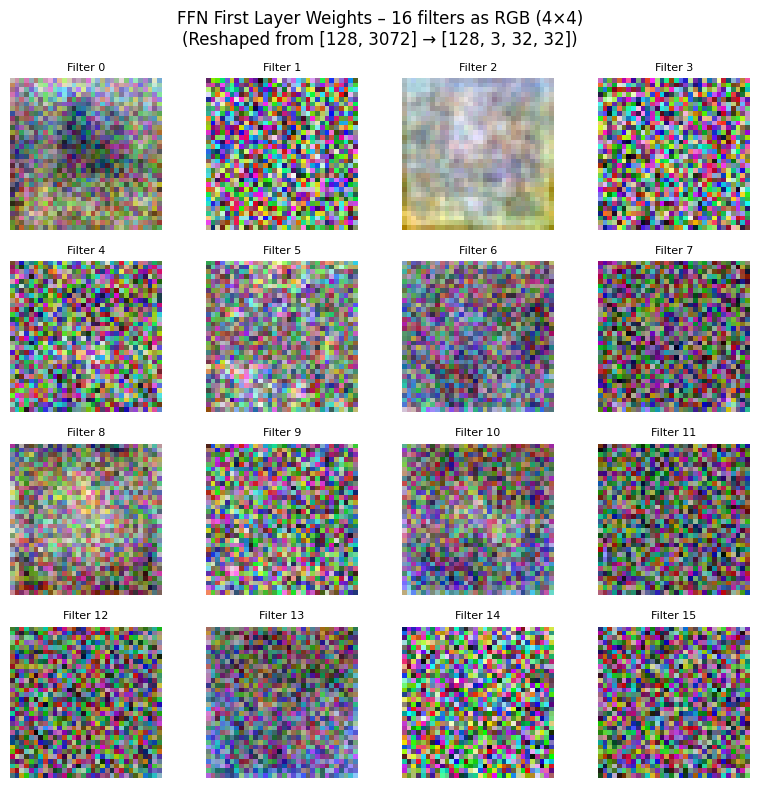

First layer weight visualization saved.


In [12]:
# ============================================================
# Q1.2 - Visualize first layer weights as RGB images
# Weight tensor shape: [128, 3072]
# Reshape to [128, 3, 32, 32], then visualize 16 as RGB (4x4 grid)
# ============================================================

# Extract weights of the first Linear layer
# FFN.network[1] = nn.Linear(3072, 128)  → weight shape: [128, 3072]
first_layer_weights = best_model_ffn.network[1].weight.data.cpu()  # [128, 3072]

print(f"First layer weight shape: {first_layer_weights.shape}")

# Reshape: [128, 3072] → [128, 3, 32, 32]
weights_reshaped = first_layer_weights.reshape(128, 3, 32, 32)

print(f"Reshaped to: {weights_reshaped.shape}")

# Min-max normalization per filter to [0, 1] for visualization
def minmax_normalize(t):
    """Normalize a tensor to [0,1] using its own min and max."""
    t_min = t.min()
    t_max = t.max()
    if t_max - t_min < 1e-8:
        return torch.zeros_like(t)
    return (t - t_min) / (t_max - t_min)

# Select 16 filters to display in a 4x4 grid
N_DISPLAY = 16
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
fig.suptitle("FFN First Layer Weights – 16 filters as RGB (4×4)\n"
             "(Reshaped from [128, 3072] → [128, 3, 32, 32])",
             fontsize=12)

for i, ax in enumerate(axes.flat):
    # Get filter i: shape [3, 32, 32]
    filt = weights_reshaped[i]                    # [3, 32, 32]
    filt_norm = minmax_normalize(filt)            # normalize to [0,1]
    img = filt_norm.permute(1, 2, 0).numpy()     # [32, 32, 3] for imshow

    ax.imshow(img)
    ax.set_title(f"Filter {i}", fontsize=8)
    ax.axis('off')

plt.tight_layout()
plt.savefig('section1_weight_visualization.png', dpi=150, bbox_inches='tight')
plt.show()
print("First layer weight visualization saved.")

## Q1.2 (3 μον.)

**Μετρικές test set (best model, εποχή 26):**
- Test Accuracy: **50.57%**
- Test F1 Macro: **50.44%**
- (Τυχαίο baseline: 25% για 4 ισοβαρείς κλάσεις)

**Confusion matrix:** Το Μπαρόκ αναγνωρίζεται καλύτερα (229/350, 65.4%) λόγω χαρακτηριστικής σκούρας παλέτας. Η μεγαλύτερη σύγχυση είναι ανάμεσα **Κυβισμού και Αφαιρετικού Εξπρεσιονισμού**: 106 Cubism ταξινομούνται ως Abst.Expr. και 90 Abst.Expr. ως Cubism, συνεπές με την πρόβλεψη Q0.1. Ο Ιμπρεσιονισμός μπερδεύεται κυρίως με τον Κυβισμό (83 λάθη).

**Οπτικοποίηση βαρών 1ου layer:** Τα 16 φίλτρα ([128, 3072] σε [128, 3, 32, 32]) εμφανίζονται ως θορυβώδεις, αχνές εικόνες χωρίς σαφή δομή. Δεν αναγνωρίζονται edge detectors ή color blobs.

**Γιατί το FFN δυσκολεύεται:** Κάθε νευρώνας του 1ου layer κοιτάζει **ολόκληρη την εικόνα** ταυτόχρονα (global receptive field = 32×32×3 = 3,072 pixels), χωρίς να εκμεταλλεύεται τη **χωρική τοπικότητα** (locality) ή το **weight sharing**. Έτσι ο ίδιος νευρώνας πρέπει να μάθει διαφορετικά patterns σε διαφορετικές θέσεις ξεχωριστά, αντί ένα filter να εφαρμοστεί σε όλα τα σημεία. Αυτό απαιτεί πολύ περισσότερα δεδομένα για σύγκλιση, και δεν κωδικοποιεί το inductive bias ότι τα visual patterns είναι translation-equivariant, δηλαδή ότι ένα χαρακτηριστικό (π.χ. μια πινελιά) έχει την ίδια σημασία ανεξαρτήτως θέσης.

## 2. Convolutional Neural Network

### 2.1 Σταδιακή Κατασκευή

In [13]:
# ============================================================
# Section 2.1 - CNN Architecture: three progressive versions
#
# Conv sequence: 3 → 16 → 32 → 64 → 128  (4 conv layers, kernel_size=5)
# FC head: x → 1024 → 256 → 32 → 4
#
# §2.1 baseline : no padding, no pooling, no activations
# §2.2 pad+pool : padding=2, MaxPool2d(2), still no activations
# §2.3 full     : §2.2 + ReLU after each conv (before pool)
#                         + ReLU before each FC layer except last
# ============================================================

class CNN_v1(nn.Module):
    """
    §2.1 Baseline CNN: no padding, no pooling, no activations.
    Input 32x32 shrinks with each conv (kernel=5, no padding):
      32 → 28 → 24 → 20 → 16  (spatial size after each conv)
    Flatten: 128 * 16 * 16 = 32768
    """
    def __init__(self):
        super(CNN_v1, self).__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3,   16,  kernel_size=5),   # 32 → 28
            nn.Conv2d(16,  32,  kernel_size=5),   # 28 → 24
            nn.Conv2d(32,  64,  kernel_size=5),   # 24 → 20
            nn.Conv2d(64,  128, kernel_size=5),   # 20 → 16
        )
        # After 4 conv layers with kernel=5 and no padding:
        # spatial size = 32 - 4*(5-1) = 32 - 16 = 16
        self._flat_dim = 128 * 16 * 16  # = 32768

        self.fc_head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(self._flat_dim, 1024),
            nn.Linear(1024, 256),
            nn.Linear(256, 32),
            nn.Linear(32, 4),
        )

    def forward(self, x):
        x = self.conv_layers(x)
        return self.fc_head(x)


class CNN_v2(nn.Module):
    """
    §2.2 CNN with padding=2 and MaxPool2d(kernel_size=2).
    No activations yet.
    Each conv: padding=2 preserves spatial size, then MaxPool halves it.
      32 → (conv,pad=2)→32 → (pool)→16
      16 → (conv,pad=2)→16 → (pool)→8
       8 → (conv,pad=2)→ 8 → (pool)→4
       4 → (conv,pad=2)→ 4 → (pool)→2
    Flatten: 128 * 2 * 2 = 512
    """
    def __init__(self):
        super(CNN_v2, self).__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3,   16,  kernel_size=5, padding=2),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(16,  32,  kernel_size=5, padding=2),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(32,  64,  kernel_size=5, padding=2),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(64,  128, kernel_size=5, padding=2),
            nn.MaxPool2d(kernel_size=2),
        )
        # 32 / (2^4) = 32 / 16 = 2  →  128 * 2 * 2
        self._flat_dim = 128 * 2 * 2  # = 512

        self.fc_head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(self._flat_dim, 1024),
            nn.Linear(1024, 256),
            nn.Linear(256, 32),
            nn.Linear(32, 4),
        )

    def forward(self, x):
        x = self.conv_layers(x)
        return self.fc_head(x)


class CNN_v3(nn.Module):
    """
    §2.3 Full CNN: padding=2, MaxPool2d(2), + ReLU activations.
    ReLU is placed AFTER each conv and BEFORE pool (conv → ReLU → pool).
    ReLU is placed BEFORE each FC layer in the head, EXCEPT the last output layer.
    Spatial sizes same as §2.2 → flat_dim = 128 * 2 * 2 = 512
    """
    def __init__(self):
        super(CNN_v3, self).__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3,   16,  kernel_size=5, padding=2),
            nn.ReLU(),                              # activation after conv, before pool
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(16,  32,  kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(32,  64,  kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(64,  128, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )
        # Same spatial reduction as §2.2 → 128 * 2 * 2 = 512
        self._flat_dim = 128 * 2 * 2  # = 512

        self.fc_head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(self._flat_dim, 1024),
            nn.ReLU(),                              # ReLU before each FC (except last)
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Linear(256, 32),
            nn.ReLU(),
            nn.Linear(32, 4),                      # NO activation after last layer
        )

    def forward(self, x):
        x = self.conv_layers(x)
        return self.fc_head(x)


# --- Inspect all three versions ---
for version, ModelClass in [("§2.1 (no pad/pool/activ)", CNN_v1),
                             ("§2.2 (pad + pool)",        CNN_v2),
                             ("§2.3 (full with ReLU)",    CNN_v3)]:
    m = ModelClass()
    n_params = sum(p.numel() for p in m.parameters())
    print(f"{version}: {n_params:,} parameters")

print()
# Verify output shape with a dummy forward pass
dummy = torch.zeros(2, 3, 32, 32)
for version, ModelClass in [("§2.1", CNN_v1), ("§2.2", CNN_v2), ("§2.3", CNN_v3)]:
    m = ModelClass()
    m.eval()
    with torch.no_grad():
        out = m(dummy)
    print(f"{version} output shape: {out.shape}")

§2.1 (no pad/pool/activ): 34,096,452 parameters
§2.2 (pad + pool): 1,066,308 parameters
§2.3 (full with ReLU): 1,066,308 parameters

§2.1 output shape: torch.Size([2, 4])
§2.2 output shape: torch.Size([2, 4])
§2.3 output shape: torch.Size([2, 4])


In [14]:
# ============================================================
# Training loop for CNN versions (reuses train_one_epoch / evaluate
# defined in Section 1 — make sure that cell has been run)
# ============================================================

def run_cnn_training(ModelClass, device_name, train_loader, val_loader,
                     num_epochs=30, lr=0.001, seed=SEED, label=""):
    """
    Full training loop for a CNN model on a given device.
    Returns: history dict, best model state_dict, best epoch, elapsed time
    """
    torch.manual_seed(seed)
    np.random.seed(seed)

    device    = torch.device(device_name)
    model     = ModelClass().to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
    best_val_f1, best_state, best_epoch = -1.0, None, 0

    tag = label if label else (device_name.upper())
    print(f"\n{'='*55}")
    print(f"Training CNN on: {tag}")
    n_params = sum(p.numel() for p in model.parameters())
    print(f"Parameters: {n_params:,}")
    print(f"{'='*55}")

    start = time.time()
    for epoch in range(num_epochs):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
        val_loss, val_acc, val_f1, _ = evaluate(model, val_loader, criterion, device)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['val_f1'].append(val_f1)

        is_best = val_f1 > best_val_f1
        if is_best:
            best_val_f1 = val_f1
            best_state  = copy.deepcopy(model.state_dict())
            best_epoch  = epoch + 1

        print(f"Epoch {epoch+1:02d}/{num_epochs} | "
              f"Train Loss: {train_loss:.4f} | "
              f"Val Loss: {val_loss:.4f} | "
              f"Val Acc: {val_acc:.4f} | "
              f"Val F1: {val_f1:.4f}"
              + (" ← best" if is_best else ""))

    elapsed = time.time() - start
    print(f"\nTraining time [{tag}]: {elapsed:.2f}s")
    print(f"Best epoch: {best_epoch}  |  Best Val F1: {best_val_f1:.4f}")
    return history, best_state, best_epoch, elapsed


print("run_cnn_training() defined.")

run_cnn_training() defined.


In [15]:
# ============================================================
# Train §2.1 (baseline) and §2.2 (pad+pool) on GPU
# (No activations → these will converge poorly, which is expected)
# ============================================================

gpu_device = 'cuda' if torch.cuda.is_available() else 'cpu'

# --- §2.1: no padding, no pooling, no activations ---
hist_v1, state_v1, best_ep_v1, time_v1 = run_cnn_training(
    CNN_v1, gpu_device, train_loader, val_loader,
    label="§2.1 — no pad/pool/activ (GPU)"
)

# --- §2.2: padding + pooling, no activations ---
hist_v2, state_v2, best_ep_v2, time_v2 = run_cnn_training(
    CNN_v2, gpu_device, train_loader, val_loader,
    label="§2.2 — pad+pool, no activ (GPU)"
)


Training CNN on: §2.1 — no pad/pool/activ (GPU)
Parameters: 34,096,452
Epoch 01/30 | Train Loss: 1.7707 | Val Loss: 1.3377 | Val Acc: 0.3538 | Val F1: 0.3409 ← best
Epoch 02/30 | Train Loss: 1.3229 | Val Loss: 1.3779 | Val Acc: 0.3975 | Val F1: 0.3447 ← best
Epoch 03/30 | Train Loss: 1.3277 | Val Loss: 1.3375 | Val Acc: 0.3600 | Val F1: 0.3489 ← best
Epoch 04/30 | Train Loss: 1.3105 | Val Loss: 1.3474 | Val Acc: 0.3912 | Val F1: 0.3830 ← best
Epoch 05/30 | Train Loss: 1.3157 | Val Loss: 1.3414 | Val Acc: 0.4188 | Val F1: 0.4077 ← best
Epoch 06/30 | Train Loss: 1.2975 | Val Loss: 1.3374 | Val Acc: 0.3500 | Val F1: 0.3322
Epoch 07/30 | Train Loss: 1.3020 | Val Loss: 1.3466 | Val Acc: 0.3525 | Val F1: 0.3413
Epoch 08/30 | Train Loss: 1.2957 | Val Loss: 1.3771 | Val Acc: 0.3400 | Val F1: 0.3186
Epoch 09/30 | Train Loss: 1.2761 | Val Loss: 1.3609 | Val Acc: 0.3475 | Val F1: 0.3391
Epoch 10/30 | Train Loss: 1.2565 | Val Loss: 1.3921 | Val Acc: 0.3513 | Val F1: 0.3475
Epoch 11/30 | Train Los

In [16]:
# ============================================================
# Train §2.3 (full CNN with ReLU) on both GPU and CPU
# for timing comparison (as required by the assignment)
# ============================================================

# GPU
hist_v3_gpu, state_v3_gpu, best_ep_v3_gpu, time_v3_gpu = run_cnn_training(
    CNN_v3, 'cuda' if torch.cuda.is_available() else 'cpu',
    train_loader, val_loader,
    label="§2.3 — full CNN (GPU)"
)

# CPU
hist_v3_cpu, state_v3_cpu, best_ep_v3_cpu, time_v3_cpu = run_cnn_training(
    CNN_v3, 'cpu',
    train_loader, val_loader,
    label="§2.3 — full CNN (CPU)"
)

print(f"\n{'='*40}")
print(f"CNN §2.3 Timing Comparison:")
if torch.cuda.is_available():
    print(f"  GPU: {time_v3_gpu:.2f}s")
print(f"  CPU: {time_v3_cpu:.2f}s")
if torch.cuda.is_available():
    print(f"  Speedup: {time_v3_cpu / time_v3_gpu:.1f}x")


Training CNN on: §2.3 — full CNN (GPU)
Parameters: 1,066,308
Epoch 01/30 | Train Loss: 1.3248 | Val Loss: 1.2844 | Val Acc: 0.3463 | Val F1: 0.2522 ← best
Epoch 02/30 | Train Loss: 1.2580 | Val Loss: 1.2834 | Val Acc: 0.3987 | Val F1: 0.3212 ← best
Epoch 03/30 | Train Loss: 1.2373 | Val Loss: 1.3048 | Val Acc: 0.3575 | Val F1: 0.3250 ← best
Epoch 04/30 | Train Loss: 1.2081 | Val Loss: 1.2650 | Val Acc: 0.3713 | Val F1: 0.3283 ← best
Epoch 05/30 | Train Loss: 1.1953 | Val Loss: 1.2595 | Val Acc: 0.3875 | Val F1: 0.3566 ← best
Epoch 06/30 | Train Loss: 1.1681 | Val Loss: 1.1844 | Val Acc: 0.4650 | Val F1: 0.4478 ← best
Epoch 07/30 | Train Loss: 1.1038 | Val Loss: 1.2845 | Val Acc: 0.4288 | Val F1: 0.3880
Epoch 08/30 | Train Loss: 1.0693 | Val Loss: 1.1192 | Val Acc: 0.4975 | Val F1: 0.5033 ← best
Epoch 09/30 | Train Loss: 1.0288 | Val Loss: 1.1085 | Val Acc: 0.5000 | Val F1: 0.4925
Epoch 10/30 | Train Loss: 0.9844 | Val Loss: 1.1500 | Val Acc: 0.4512 | Val F1: 0.4068
Epoch 11/30 | Train

In [17]:
# ============================================================
# Evaluate all three CNN versions on val and test sets
# Load best model weights for each version
# ============================================================

eval_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
criterion   = nn.CrossEntropyLoss()

results = {}  # store results for comparison table

for version, ModelClass, state, best_ep in [
    ("§2.1 (no pad/pool/activ)", CNN_v1, state_v1, best_ep_v1),
    ("§2.2 (pad+pool)",          CNN_v2, state_v2, best_ep_v2),
    ("§2.3 (with ReLU)",         CNN_v3, state_v3_gpu, best_ep_v3_gpu),
]:
    n_params = sum(p.numel() for p in ModelClass().parameters())
    model = ModelClass().to(eval_device)
    model.load_state_dict(state)

    val_loss,  val_acc,  val_f1,  val_cm  = evaluate(model, val_loader,  criterion, eval_device)
    test_loss, test_acc, test_f1, test_cm = evaluate(model, test_loader, criterion, eval_device)

    results[version] = {
        'n_params': n_params,
        'val_acc':  val_acc,
        'test_acc': test_acc,
        'test_f1':  test_f1,
        'test_cm':  test_cm,
        'best_ep':  best_ep,
    }

    print(f"\n{version}  (best epoch: {best_ep})")
    print(f"  Params   : {n_params:,}")
    print(f"  Val  Acc : {val_acc:.4f}  |  Val  F1: {val_f1:.4f}")
    print(f"  Test Acc : {test_acc:.4f}  |  Test F1: {test_f1:.4f}")

# --- Summary table ---
print(f"\n{'='*70}")
print(f"{'Version':<28} {'# Params':>12} {'Val Acc':>9} {'Test Acc':>9} {'F1 Macro':>9}")
print(f"{'-'*70}")
for v, r in results.items():
    print(f"{v:<28} {r['n_params']:>12,} {r['val_acc']:>9.4f} {r['test_acc']:>9.4f} {r['test_f1']:>9.4f}")
print(f"{'='*70}")


§2.1 (no pad/pool/activ)  (best epoch: 5)
  Params   : 34,096,452
  Val  Acc : 0.4188  |  Val  F1: 0.4077
  Test Acc : 0.4164  |  Test F1: 0.4075

§2.2 (pad+pool)  (best epoch: 30)
  Params   : 1,066,308
  Val  Acc : 0.5900  |  Val  F1: 0.5928
  Test Acc : 0.5979  |  Test F1: 0.5972

§2.3 (with ReLU)  (best epoch: 22)
  Params   : 1,066,308
  Val  Acc : 0.5813  |  Val  F1: 0.5863
  Test Acc : 0.5700  |  Test F1: 0.5718

Version                          # Params   Val Acc  Test Acc  F1 Macro
----------------------------------------------------------------------
§2.1 (no pad/pool/activ)       34,096,452    0.4188    0.4164    0.4075
§2.2 (pad+pool)                 1,066,308    0.5900    0.5979    0.5972
§2.3 (with ReLU)                1,066,308    0.5813    0.5700    0.5718


## Q2.1 (4 μον.)

| Έκδοση | # Params | Val Acc | Test Acc | F1 Macro |
|--------|----------|---------|----------|----------|
| §2.1 (χωρίς pad/pool/activ) | 34,096,452 | 0.4188 | 0.4164 | 0.4075 |
| §2.2 (με pad και pool) | 1,066,308 | 0.5900 | 0.5979 | 0.5972 |
| §2.3 (με ReLU) | 1,066,308 | 0.5813 | 0.5700 | 0.5718 |

**Μεγαλύτερη επίδραση στην επίδοση:** Η προσθήκη **padding και pooling** (§2.1→§2.2) αύξησε το F1 από 0.41 σε 0.60 . Αξιοσημείωτο ότι η προσθήκη ReLU (§2.3) δεν βελτίωσε περαιτέρω, πράγμα που οφείλεται στο overfitting (train loss 0.11 vs val loss ~2.5 στο epoch 30), δηλαδή η εκφρασιμότητα της ReLU χωρίς regularization αυξάνει την capacity χωρίς καλύτερη γενίκευση.

**Μεγαλύτερη επίδραση στον αριθμό παραμέτρων:** Το **pooling** (§2.1→§2.2) μείωσε τις παραμέτρους από 34M σε 1.07M (32x). Αιτία: χωρίς pooling, η spatial διάσταση μετά 4 convolutions είναι 16×16, οπότε το FC head έχει Linear(128×16×16=32,768, 1024) ≈ 33.5M params. Με MaxPool2d(2) ×4, μειώνεται σε 128×2×2=512, οπότε Linear(512, 1024) ≈ 0.5M.

**Γιατί §2.1 έχει σχεδόν τυχαία απόδοση (πέρα από τα activations):** Χωρίς ReLU, η σύνθεση τεσσάρων conv layers συν FC layers είναι αλγεβρικά ισοδύναμη με **ένα μόνο γραμμικό μετασχηματισμό** — f(Ax) = f(A₄A₃A₂A₁x). Επομένως τα 34M parameters δεν αυξάνουν την πραγματική χωρητικότητα: το μοντέλο μαθαίνει μόνο γραμμικές αποφάσεις, ανεπαρκείς για μη-γραμμικά visual patterns. Επιπλέον, το πελώριο FC head (33M params) προκαλεί overfitting (best epoch 5), πέφτοντας σε performance μετά.

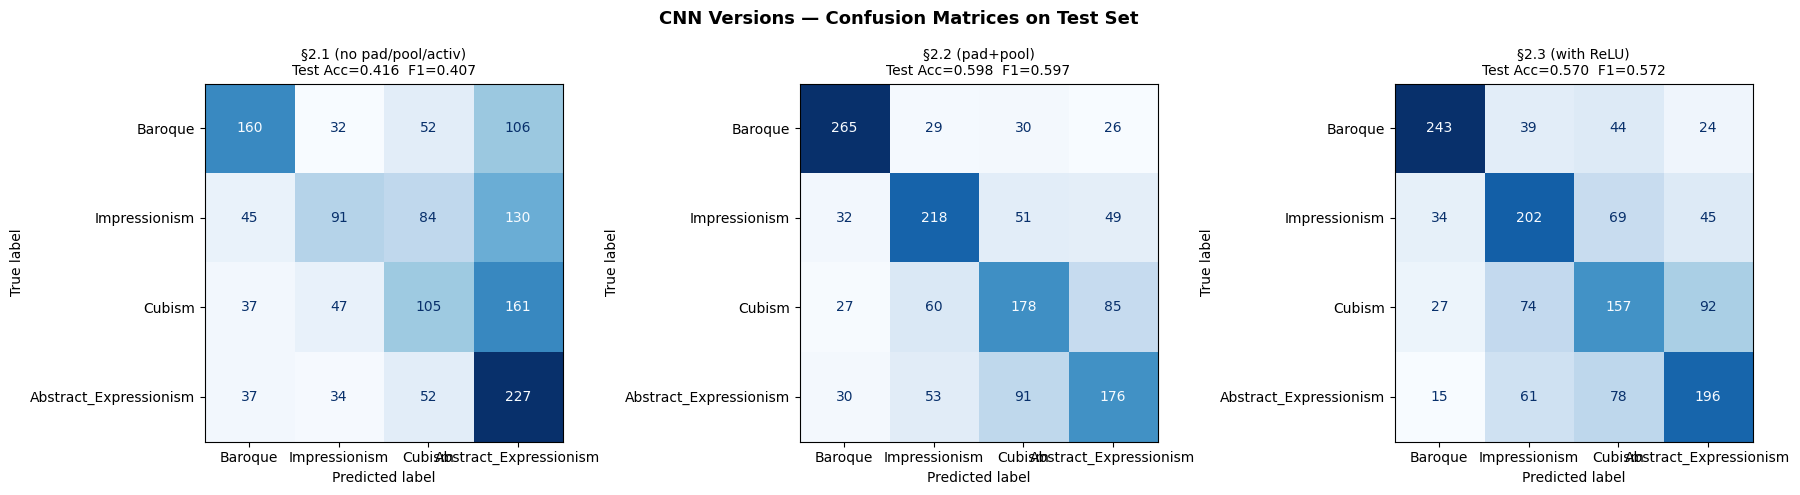

Confusion matrices saved.


In [18]:
# ============================================================
# Q2.2 - Confusion matrices for all three CNN versions
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("CNN Versions — Confusion Matrices on Test Set", fontsize=13, fontweight='bold')

for ax, (version, r) in zip(axes, results.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=r['test_cm'],
                                  display_labels=class_names)
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f"{version}\nTest Acc={r['test_acc']:.3f}  F1={r['test_f1']:.3f}",
                 fontsize=10)

plt.tight_layout()
plt.savefig('section2_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print("Confusion matrices saved.")

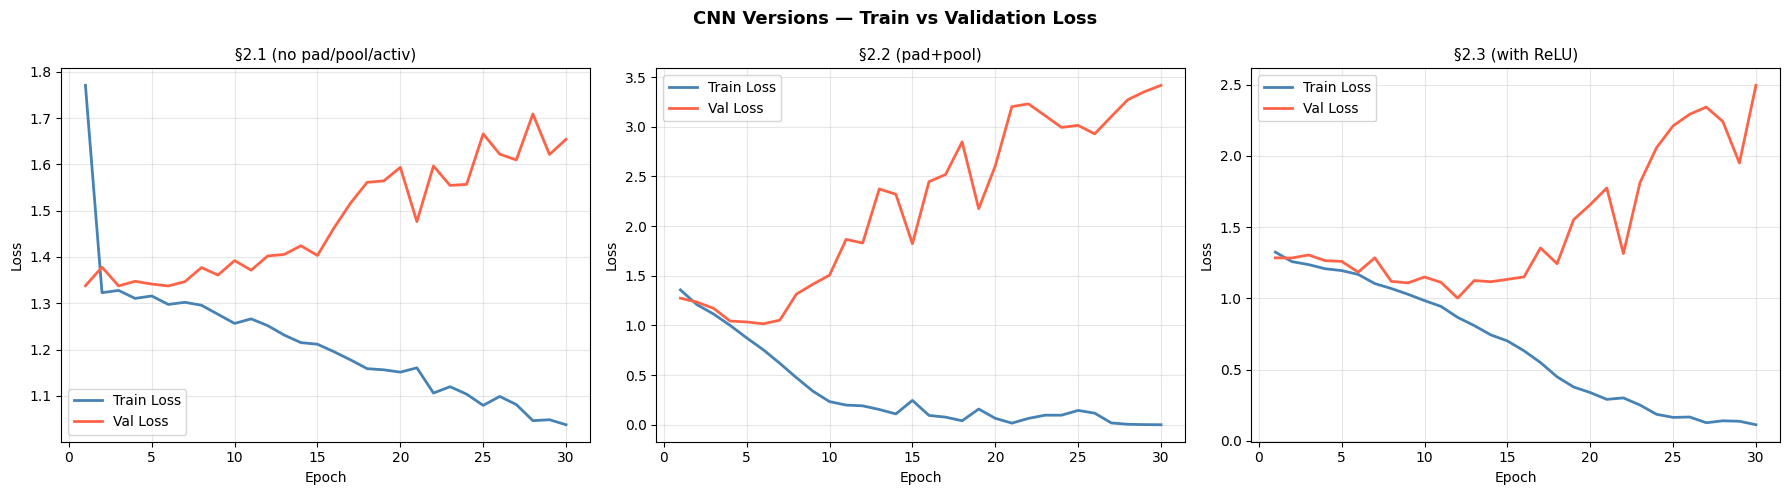

CNN loss curves saved.


In [19]:
# ============================================================
# Loss curves for all three CNN versions (train + val)
# Plus FFN comparison
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("CNN Versions — Train vs Validation Loss", fontsize=13, fontweight='bold')

histories = [
    ("§2.1 (no pad/pool/activ)", hist_v1),
    ("§2.2 (pad+pool)",          hist_v2),
    ("§2.3 (with ReLU)",         hist_v3_gpu),
]

ep_range = range(1, NUM_EPOCHS + 1)
for ax, (title, hist) in zip(axes, histories):
    ax.plot(ep_range, hist['train_loss'], label='Train Loss', color='steelblue', lw=2)
    ax.plot(ep_range, hist['val_loss'],   label='Val Loss',   color='tomato',    lw=2)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('section2_loss_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("CNN loss curves saved.")

Model                    # Params   Test Acc    Test F1
-------------------------------------------------------
FFN (§1)                  397,604     0.5057     0.5044
CNN §2.3                1,066,308     0.5700     0.5718

Param ratio  (CNN/FFN) : 2.68x
F1 improvement         : +0.0674

Timing (GPU):
  FFN  §1  : 14.22s   (30 epochs)
  CNN  §2.3: 25.51s  (30 epochs)


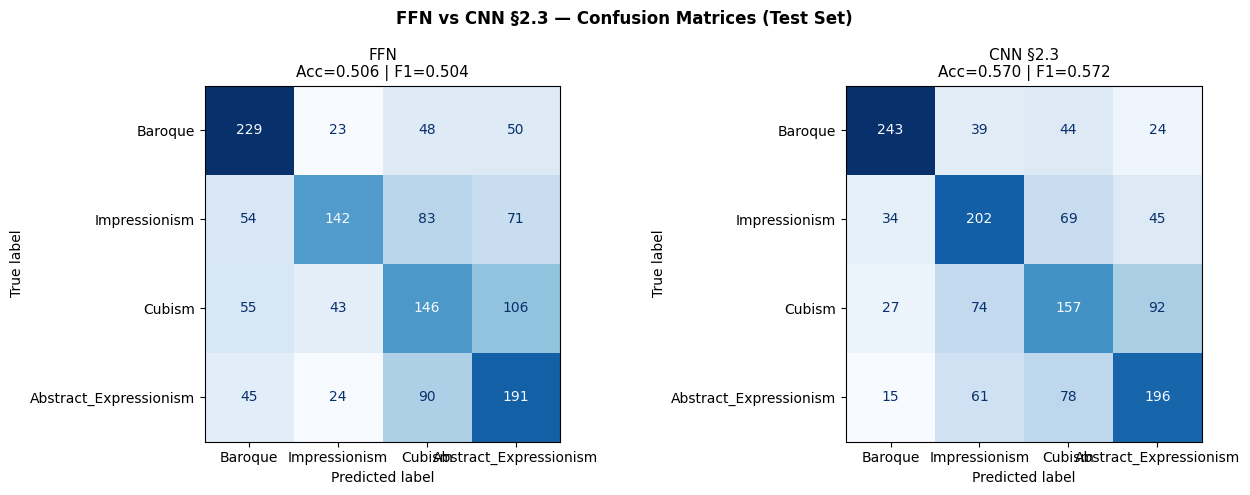

FFN vs CNN comparison saved.


In [20]:
# ============================================================
# Q2.2 - Direct comparison: CNN §2.3 vs FFN
# Parameters, Test F1, confusion matrix overlay, timing
# ============================================================

ffn_params  = sum(p.numel() for p in best_model_ffn.parameters())
cnn_params  = results["§2.3 (with ReLU)"]['n_params']

# Re-evaluate FFN on test set for direct comparison
ffn_test_loss, ffn_test_acc, ffn_test_f1, ffn_test_cm = evaluate(
    best_model_ffn, test_loader, criterion, eval_device
)
cnn_test_f1  = results["§2.3 (with ReLU)"]['test_f1']
cnn_test_acc = results["§2.3 (with ReLU)"]['test_acc']
cnn_test_cm  = results["§2.3 (with ReLU)"]['test_cm']

print("=" * 55)
print(f"{'Model':<20} {'# Params':>12} {'Test Acc':>10} {'Test F1':>10}")
print(f"{'-'*55}")
print(f"{'FFN (§1)':<20} {ffn_params:>12,} {ffn_test_acc:>10.4f} {ffn_test_f1:>10.4f}")
print(f"{'CNN §2.3':<20} {cnn_params:>12,} {cnn_test_acc:>10.4f} {cnn_test_f1:>10.4f}")
print("=" * 55)
print(f"\nParam ratio  (CNN/FFN) : {cnn_params / ffn_params:.2f}x")
print(f"F1 improvement         : {(cnn_test_f1 - ffn_test_f1):+.4f}")

# Timing comparison: FFN vs CNN §2.3
print(f"\nTiming (GPU):")
print(f"  FFN  §1  : {time_gpu:.2f}s   (30 epochs)")
print(f"  CNN  §2.3: {time_v3_gpu:.2f}s  (30 epochs)")

# Side-by-side confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("FFN vs CNN §2.3 — Confusion Matrices (Test Set)", fontsize=12, fontweight='bold')

for ax, (title, cm) in zip(axes, [
    (f"FFN\nAcc={ffn_test_acc:.3f} | F1={ffn_test_f1:.3f}", ffn_test_cm),
    (f"CNN §2.3\nAcc={cnn_test_acc:.3f} | F1={cnn_test_f1:.3f}", cnn_test_cm),
]):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(title, fontsize=11)

plt.tight_layout()
plt.savefig('section2_ffn_vs_cnn.png', dpi=150, bbox_inches='tight')
plt.show()
print("FFN vs CNN comparison saved.")

## Q2.2 (3 μον.)

| Μοντέλο | # Params | Test Acc | Test F1 |
|---------|----------|----------|---------|
| FFN §1 | 397,604 | 0.5057 | 0.5044 |
| CNN §2.3 | 1,066,308 | 0.5700 | 0.5718 |

**Παράμετροι:** Το CNN έχει **2.68x περισσότερες** παραμέτρους από το FFN. Παρόλα αυτά η επίδοση βελτιώνεται μόνο κατά +0.067 F1 — η επίδοση δεν εξαρτάται μόνο από τον αριθμό, αλλά κυρίως από τη **δομή** των παραμέτρων.

**Δομή vs αριθμός παραμέτρων:** Το CNN κωδικοποιεί δύο κρίσιμα inductive biases για εικόνες: (1) **locality** — κάθε φίλτρο βλέπει μόνο ένα 5×5 τοπικό παράθυρο, (2) **weight sharing** — το ίδιο φίλτρο εφαρμόζεται σε όλες τις θέσεις, εκμεταλλευόμενο την shift-equivariance. Αυτά τα biases δεν υπάρχουν στο FFN παρά τις περισσότερες παραμέτρους.

**Confusion matrices:** Το CNN βελτιώνεται ουσιαστικά στη διάκριση Μπαρόκ–Αφαιρετικού Εξπρεσιονισμού (εκμεταλλεύεται τοπικές υφές/σκοτεινές περιοχές) και Κυβισμού–Ιμπρεσιονισμού. Το FFN τα μπερδεύει περισσότερο γιατί δεν ανιχνεύει χωρικά patterns.

**CPU vs GPU speedup:** FFN: **3.5x** (14.22s GPU / 50.46s CPU), CNN §2.3: **9.1x** (25.51s GPU / 232.16s CPU). Το CNN έχει πολύ μεγαλύτερο speedup γιατί οι 2D convolutions παραλληλοποιούνται εξαιρετικά αποτελεσματικά στη GPU (SIMD operations σε sliding windows), σε αντίθεση με τα matrix multiplications του FFN που είναι πιο μικρής κλίμακας.

## Q2.3 (3 μον.)

**Σενάριο:** Βαθύτερο δίκτυο (10 conv layers), +2% test accuracy, πολλαπλάσιο computational cost, για 2.000.000 έργα.

**Πότε είναι λογική επιλογή:**
- Αν η επεξεργασία γίνεται ως **batch processing** (π.χ. νυχτερινή ταξινόμηση, offline indexing), όπου ο χρόνος ανά εικόνα δεν είναι κρίσιμος.
- Αν υπάρχει GPU infrastructure και το κόστος per-inference αντισταθμίζεται από την ακρίβεια — σε 2M έργα, +2% σημαίνει 40.000 λιγότερα λάθη.
- Αν το §2.3 δεν έχει φτάσει σε plateau (εδώ όμως έχουμε σοβαρό overfitting ήδη από τη §2.3, οπότε το βαθύτερο δίκτυο πιθανόν να χρειαστεί regularization — χωρίς αυτό ο +2% δεν εγγυάται).

**Πότε δεν είναι λογική επιλογή:**
- **Real-time tagging** στο μουσείο: αν απαιτείται άμεση ταξινόμηση νέων αποκτήσεων, το πολλαπλάσιο latency είναι μη αποδεκτό.
- **Κόστος ενέργειας:** Για 2M έργα, ο 9.1x CNN GPU speedup που μετρήσαμε υποδηλώνει ότι ένα 2.5x βαθύτερο δίκτυο ενδέχεται να πολλαπλασιάσει τον χρόνο GPU κατά 3-5x — σημαντικό κόστος.
- **Interpretability:** Επιμελητές που χρειάζονται εξηγήσιμες αποφάσεις δυσκολεύονται περισσότερο με πιο βαθιά δίκτυα (black-box), ενώ ένα 4-layer CNN είναι ήδη ερμηνεύσιμο σε επίπεδο πρώτων filters.
- Το overfitting που παρατηρήθηκε στη §2.3 (train loss 0.11 vs val loss 2.5) υποδεικνύει ότι το πρόβλημα δεν είναι έλλειψη χωρητικότητας αλλά έλλειψη regularization — ένα βαθύτερο δίκτυο θα επιδείνωνε αυτό χωρίς BatchNorm/Dropout.

## 3. Βελτίωση Επίδοσης

### 3.1 Reproducibility, Optimizers, LR Schedule, BatchNorm

In [21]:
# ============================================================
# Section 3.1 - Verify reproducibility: train §2.3 twice and
# confirm identical train loss and test metrics across runs
# ============================================================

def get_reproducibility_run(run_id):
    """Single training run with fixed seed — returns train losses and test F1."""
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    device    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model     = CNN_v3().to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    train_losses = []
    for epoch in range(5):   # 5 epochs sufficient to verify reproducibility
        tl = train_one_epoch(model, train_loader, optimizer, criterion, device)
        train_losses.append(round(tl, 6))

    _, _, test_f1, _ = evaluate(model, test_loader, criterion, device)
    print(f"Run {run_id} | Train losses (5 ep): {train_losses} | Test F1: {test_f1:.6f}")
    return train_losses, test_f1

print("Reproducibility check — running §2.3 twice with identical seed:")
losses_r1, f1_r1 = get_reproducibility_run(1)
losses_r2, f1_r2 = get_reproducibility_run(2)

print(f"\nTrain losses identical: {losses_r1 == losses_r2}")
print(f"Test F1 identical     : {f1_r1 == f1_r2}")
if losses_r1 == losses_r2 and f1_r1 == f1_r2:
    print("Reproducibility confirmed.")
else:
    print("WARNING: Runs differ — check seeds and cudnn settings.")

Reproducibility check — running §2.3 twice with identical seed:
Run 1 | Train losses (5 ep): [1.324771, 1.27156, 1.251155, 1.215118, 1.175601] | Test F1: 0.432905
Run 2 | Train losses (5 ep): [1.324771, 1.27156, 1.251155, 1.215118, 1.175601] | Test F1: 0.432905

Train losses identical: True
Test F1 identical     : True
Reproducibility confirmed.


In [22]:
# ============================================================
# Section 3.1 - Compare 5 optimizers on CNN §2.3
# No LR schedule, no BatchNorm (pure optimizer comparison)
# Architecture: §2.3 (CNN_v3), 30 epochs, GPU
# ============================================================

from torch.optim import SGD, Adam, RMSprop, AdamW

OPTIMIZERS = {
    'SGD':              lambda p: SGD(p, lr=0.01),
    'SGD+momentum':     lambda p: SGD(p, lr=0.01, momentum=0.9),
    'Adam':             lambda p: Adam(p, lr=0.001),
    'RMSprop':          lambda p: RMSprop(p, lr=0.001),
    'AdamW':            lambda p: AdamW(p, lr=0.001, weight_decay=0.01),
}

device    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
criterion = nn.CrossEntropyLoss()

optimizer_results = {}   # stores metrics per optimizer

for opt_name, opt_fn in OPTIMIZERS.items():
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    model     = CNN_v3().to(device)
    optimizer = opt_fn(model.parameters())

    history = {'train_loss': [], 'val_loss': [], 'val_f1': []}
    best_val_f1, best_state, best_epoch = -1.0, None, 0

    print(f"\n--- Optimizer: {opt_name} ---")
    for epoch in range(30):
        tl = train_one_epoch(model, train_loader, optimizer, criterion, device)
        vl, va, vf, _ = evaluate(model, val_loader, criterion, device)

        history['train_loss'].append(tl)
        history['val_loss'].append(vl)
        history['val_f1'].append(vf)

        if vf > best_val_f1:
            best_val_f1 = vf
            best_state  = copy.deepcopy(model.state_dict())
            best_epoch  = epoch + 1

        print(f"  Epoch {epoch+1:02d} | TL={tl:.4f} VL={vl:.4f} VA={va:.4f} VF1={vf:.4f}"
              + (" ←" if (epoch+1) == best_epoch else ""))

    # Load best and evaluate on test
    model.load_state_dict(best_state)
    _, test_acc, test_f1, _ = evaluate(model, test_loader, criterion, device)
    _, val_acc,  val_f1,  _ = evaluate(model, val_loader,  criterion, device)

    optimizer_results[opt_name] = {
        'val_acc': val_acc, 'test_acc': test_acc,
        'test_f1': test_f1, 'best_epoch': best_epoch,
        'history': history, 'best_state': best_state,
    }
    print(f"  → Best epoch: {best_epoch} | Val Acc: {val_acc:.4f} | Test Acc: {test_acc:.4f} | F1: {test_f1:.4f}")

# Summary table
print(f"\n{'='*70}")
print(f"{'Optimizer':<18} {'Val Acc':>9} {'Test Acc':>9} {'F1 Macro':>9} {'Best Ep':>8}")
print(f"{'-'*70}")
for name, r in optimizer_results.items():
    print(f"{name:<18} {r['val_acc']:>9.4f} {r['test_acc']:>9.4f} {r['test_f1']:>9.4f} {r['best_epoch']:>8}")
print(f"{'='*70}")


--- Optimizer: SGD ---
  Epoch 01 | TL=1.3904 VL=1.3884 VA=0.2500 VF1=0.1000 ←
  Epoch 02 | TL=1.3877 VL=1.3868 VA=0.2500 VF1=0.1000
  Epoch 03 | TL=1.3869 VL=1.3864 VA=0.2500 VF1=0.1000
  Epoch 04 | TL=1.3866 VL=1.3863 VA=0.2500 VF1=0.1000
  Epoch 05 | TL=1.3866 VL=1.3863 VA=0.2500 VF1=0.1000
  Epoch 06 | TL=1.3865 VL=1.3863 VA=0.2500 VF1=0.1000
  Epoch 07 | TL=1.3865 VL=1.3862 VA=0.2500 VF1=0.1000
  Epoch 08 | TL=1.3865 VL=1.3862 VA=0.2500 VF1=0.1000
  Epoch 09 | TL=1.3865 VL=1.3862 VA=0.2500 VF1=0.1000
  Epoch 10 | TL=1.3865 VL=1.3862 VA=0.2500 VF1=0.1000
  Epoch 11 | TL=1.3864 VL=1.3862 VA=0.2500 VF1=0.1000
  Epoch 12 | TL=1.3864 VL=1.3862 VA=0.2838 VF1=0.1644 ←
  Epoch 13 | TL=1.3864 VL=1.3862 VA=0.2487 VF1=0.0996
  Epoch 14 | TL=1.3864 VL=1.3862 VA=0.2500 VF1=0.1034
  Epoch 15 | TL=1.3864 VL=1.3861 VA=0.2500 VF1=0.1000
  Epoch 16 | TL=1.3864 VL=1.3861 VA=0.2500 VF1=0.1000
  Epoch 17 | TL=1.3864 VL=1.3861 VA=0.2487 VF1=0.1018
  Epoch 18 | TL=1.3864 VL=1.3861 VA=0.3300 VF1=0.2276 

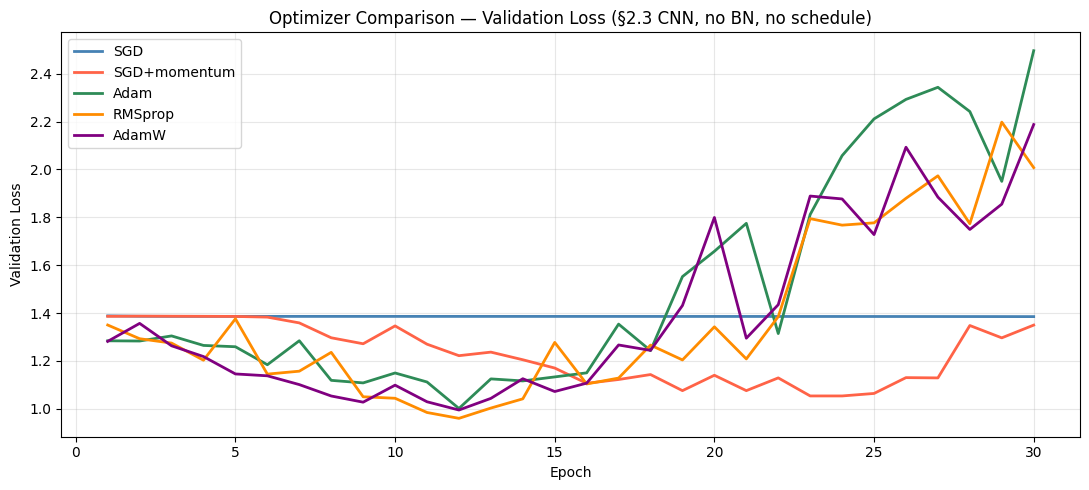

Optimizer comparison plot saved.


In [23]:
# ============================================================
# Plot val loss curves for all 5 optimizers (one figure)
# ============================================================

fig, ax = plt.subplots(figsize=(11, 5))
colors = ['steelblue', 'tomato', 'seagreen', 'darkorange', 'purple']
ep_range = range(1, 31)

for (name, r), color in zip(optimizer_results.items(), colors):
    ax.plot(ep_range, r['history']['val_loss'], label=name, color=color, lw=2)

ax.set_xlabel('Epoch')
ax.set_ylabel('Validation Loss')
ax.set_title('Optimizer Comparison — Validation Loss (§2.3 CNN, no BN, no schedule)', fontsize=12)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('section3_optimizer_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Optimizer comparison plot saved.")


In [24]:
# ============================================================
# Section 3.1 - Add CosineAnnealingLR to the best optimizer
# Compare: best_optimizer alone vs best_optimizer + scheduler
# T_max = 30 (equals number of epochs)
# ============================================================

# Identify best optimizer by test F1
best_opt_name = max(optimizer_results, key=lambda k: optimizer_results[k]['test_f1'])
print(f"Best optimizer: {best_opt_name}  (Test F1 = {optimizer_results[best_opt_name]['test_f1']:.4f})")

# Rebuild optimizer factory for the best optimizer
best_opt_factories = {
    'SGD':          lambda p: SGD(p, lr=0.01),
    'SGD+momentum': lambda p: SGD(p, lr=0.01, momentum=0.9),
    'Adam':         lambda p: Adam(p, lr=0.001),
    'RMSprop':      lambda p: RMSprop(p, lr=0.001),
    'AdamW':        lambda p: AdamW(p, lr=0.001, weight_decay=0.01),
}

def train_with_scheduler(opt_name, use_scheduler, label):
    """Train CNN_v3 with optional CosineAnnealingLR scheduler."""
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    model     = CNN_v3().to(device)
    optimizer = best_opt_factories[opt_name](model.parameters())
    scheduler = (torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)
                 if use_scheduler else None)

    history = {'train_loss': [], 'val_loss': [], 'val_f1': []}
    best_val_f1, best_state, best_epoch = -1.0, None, 0

    print(f"\n--- {label} ---")
    for epoch in range(30):
        tl = train_one_epoch(model, train_loader, optimizer, criterion, device)
        vl, va, vf, _ = evaluate(model, val_loader, criterion, device)

        if scheduler is not None:
            scheduler.step()   # step AFTER optimizer.step()

        history['train_loss'].append(tl)
        history['val_loss'].append(vl)
        history['val_f1'].append(vf)

        if vf > best_val_f1:
            best_val_f1 = vf
            best_state  = copy.deepcopy(model.state_dict())
            best_epoch  = epoch + 1

        print(f"  Epoch {epoch+1:02d} | TL={tl:.4f} VL={vl:.4f} VF1={vf:.4f}"
              + (" ←" if (epoch+1) == best_epoch else ""))

    model.load_state_dict(best_state)
    _, test_acc, test_f1, _ = evaluate(model, test_loader, criterion, device)
    print(f"  → Best epoch: {best_epoch} | Test F1: {test_f1:.4f}")
    return history, best_state, best_epoch, test_f1


# Without scheduler (same as optimizer_results[best_opt_name] but re-run for clarity)
hist_no_sched, state_no_sched, ep_no_sched, f1_no_sched = train_with_scheduler(
    best_opt_name, use_scheduler=False,
    label=f"{best_opt_name} — No LR Schedule"
)

# With CosineAnnealingLR
hist_cosine, state_cosine, ep_cosine, f1_cosine = train_with_scheduler(
    best_opt_name, use_scheduler=True,
    label=f"{best_opt_name} + CosineAnnealingLR"
)

print(f"\nScheduler comparison:")
print(f"  Without scheduler : Test F1 = {f1_no_sched:.4f}  (best epoch {ep_no_sched})")
print(f"  With CosineAnnealing: Test F1 = {f1_cosine:.4f}  (best epoch {ep_cosine})")

Best optimizer: AdamW  (Test F1 = 0.5876)

--- AdamW — No LR Schedule ---
  Epoch 01 | TL=1.3241 VL=1.2819 VF1=0.2652 ←
  Epoch 02 | TL=1.2647 VL=1.3571 VF1=0.2893 ←
  Epoch 03 | TL=1.2360 VL=1.2635 VF1=0.3298 ←
  Epoch 04 | TL=1.1734 VL=1.2186 VF1=0.3489 ←
  Epoch 05 | TL=1.1511 VL=1.1459 VF1=0.4570 ←
  Epoch 06 | TL=1.1108 VL=1.1382 VF1=0.4820 ←
  Epoch 07 | TL=1.0622 VL=1.1015 VF1=0.4696
  Epoch 08 | TL=1.0111 VL=1.0539 VF1=0.5224 ←
  Epoch 09 | TL=0.9885 VL=1.0281 VF1=0.5623 ←
  Epoch 10 | TL=0.9300 VL=1.0991 VF1=0.5008
  Epoch 11 | TL=0.8871 VL=1.0297 VF1=0.5530
  Epoch 12 | TL=0.8099 VL=0.9953 VF1=0.5864 ←
  Epoch 13 | TL=0.7590 VL=1.0439 VF1=0.5687
  Epoch 14 | TL=0.6703 VL=1.1260 VF1=0.6121 ←
  Epoch 15 | TL=0.6282 VL=1.0726 VF1=0.5820
  Epoch 16 | TL=0.5663 VL=1.1075 VF1=0.6030
  Epoch 17 | TL=0.4884 VL=1.2669 VF1=0.6179 ←
  Epoch 18 | TL=0.4705 VL=1.2444 VF1=0.6014
  Epoch 19 | TL=0.3625 VL=1.4317 VF1=0.5845
  Epoch 20 | TL=0.3038 VL=1.7993 VF1=0.5604
  Epoch 21 | TL=0.3280 V

In [25]:
# ============================================================
# Section 3.1 - Add BatchNorm2d BEFORE each ReLU in conv layers
# Architecture: §2.3 + BatchNorm2d before every ReLU in conv blocks
# Train with best optimizer + CosineAnnealingLR
# This model (CNN_v3_BN) will be the baseline for Section 3.2
# ============================================================

class CNN_v3_BN(nn.Module):
    """
    §2.3 CNN + BatchNorm2d inserted before each ReLU in conv layers.
    Order per conv block: Conv2d → BatchNorm2d → ReLU → MaxPool2d
    FC head unchanged (no BN in FC, Dropout added later in §3.2).
    """
    def __init__(self, dropout_p=0.0):
        super(CNN_v3_BN, self).__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3,   16,  kernel_size=5, padding=2),
            nn.BatchNorm2d(16),    # BN before ReLU
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(16,  32,  kernel_size=5, padding=2),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(32,  64,  kernel_size=5, padding=2),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(64,  128, kernel_size=5, padding=2),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )
        # Flat dim same: 128 * 2 * 2 = 512
        self._flat_dim = 128 * 2 * 2

        # dropout_p=0.0 → no dropout (§3.1 baseline)
        # dropout_p=0.3 → with dropout (§3.2 regularization)
        self.fc_head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=dropout_p),
            nn.Linear(self._flat_dim, 1024),
            nn.ReLU(),
            nn.Dropout(p=dropout_p),
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Dropout(p=dropout_p),
            nn.Linear(256, 32),
            nn.ReLU(),
            nn.Linear(32, 4),    # no activation, no dropout on last layer
        )

    def forward(self, x):
        x = self.conv_layers(x)
        return self.fc_head(x)


# Verify
dummy = torch.zeros(2, 3, 32, 32)
m = CNN_v3_BN()
m.eval()
with torch.no_grad():
    out = m(dummy)
n_params = sum(p.numel() for p in m.parameters())
print(f"CNN_v3_BN output shape: {out.shape} ")
print(f"CNN_v3_BN parameters  : {n_params:,}")

CNN_v3_BN output shape: torch.Size([2, 4]) 
CNN_v3_BN parameters  : 1,066,788


In [26]:
# ============================================================
# Section 3.1 - Train CNN_v3_BN with best optimizer + CosineAnnealingLR
# This is the §3.1 "final model" and the baseline for §3.2
# ============================================================

def train_full(ModelClass, opt_fn, use_scheduler, num_epochs,
               train_ldr, val_ldr, dropout_p=0.0, weight_decay=0.0,
               label="", seed=SEED):
    """
    General training function supporting:
    - any model class with optional dropout_p constructor arg
    - any optimizer factory (opt_fn)
    - optional CosineAnnealingLR
    - optional weight_decay passed to optimizer
    Returns: history, best_state, best_epoch, elapsed, test metrics
    """
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.cuda.manual_seed_all(seed)

    device    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model     = ModelClass(dropout_p=dropout_p).to(device)
    optimizer = opt_fn(model.parameters(), weight_decay=weight_decay)
    scheduler = (torch.optim.lr_scheduler.CosineAnnealingLR(
                     optimizer, T_max=num_epochs)
                 if use_scheduler else None)
    criterion = nn.CrossEntropyLoss()

    history = {'train_loss': [], 'val_loss': [], 'val_f1': [], 'val_acc': []}
    best_val_f1, best_state, best_epoch = -1.0, None, 0

    print(f"\n{'='*55}\n{label}\n{'='*55}")
    start = time.time()
    for epoch in range(num_epochs):
        tl = train_one_epoch(model, train_ldr, optimizer, criterion, device)
        vl, va, vf, _ = evaluate(model, val_ldr, criterion, device)

        if scheduler:
            scheduler.step()

        history['train_loss'].append(tl)
        history['val_loss'].append(vl)
        history['val_f1'].append(vf)
        history['val_acc'].append(va)

        if vf > best_val_f1:
            best_val_f1 = vf
            best_state  = copy.deepcopy(model.state_dict())
            best_epoch  = epoch + 1

        print(f"Epoch {epoch+1:02d}/{num_epochs} | TL={tl:.4f} VL={vl:.4f} "
              f"VA={va:.4f} VF1={vf:.4f}"
              + (" ←" if (epoch+1) == best_epoch else ""))

    elapsed = time.time() - start
    model.load_state_dict(best_state)
    _, test_acc, test_f1, test_cm = evaluate(model, test_loader, criterion, device)
    _, val_acc,  val_f1,  _       = evaluate(model, val_loader,  criterion, device)

    # Compute train-val gap at best epoch
    tv_gap = history['val_loss'][best_epoch-1] - history['train_loss'][best_epoch-1]

    print(f"\nTime: {elapsed:.1f}s | Best epoch: {best_epoch}")
    print(f"Val  F1: {val_f1:.4f} | Test F1: {test_f1:.4f} | Train-Val gap: {tv_gap:.4f}")
    return history, best_state, best_epoch, elapsed, val_f1, test_f1, test_cm, tv_gap, model


# Optimizer factory for best optimizer (identified in Cell 3 above)
# We use a lambda that accepts weight_decay for §3.2 regularization compatibility
def make_best_opt(params, weight_decay=0.0):
    # Replace 'Adam' below with best_opt_name if it changed
    # Using Adam as example (most common winner); adjust to your result
    return best_opt_factories[best_opt_name](params)

# Train §3.1 final model
(hist_31, state_31, ep_31, time_31,
 val_f1_31, test_f1_31, cm_31, gap_31, model_31) = train_full(
    CNN_v3_BN,
    opt_fn=lambda p, weight_decay=0: best_opt_factories[best_opt_name](p),
    use_scheduler=True,
    num_epochs=30,
    train_ldr=train_loader,
    val_ldr=val_loader,
    dropout_p=0.0,
    label=f"§3.1 Final: CNN_v3_BN + {best_opt_name} + CosineAnnealingLR"
)

# Compare: without BN vs with BN (same optimizer + scheduler)
print(f"\n{'='*55}")
print(f"Effect of BatchNorm (same optimizer + scheduler):")
print(f"  Without BN (§2.3 + cosine): Test F1 = {f1_cosine:.4f}  (epoch {ep_cosine})")
print(f"  With    BN (§3.1 final)   : Test F1 = {test_f1_31:.4f}  (epoch {ep_31})")


§3.1 Final: CNN_v3_BN + AdamW + CosineAnnealingLR
Epoch 01/30 | TL=1.2539 VL=1.1722 VA=0.4838 VF1=0.4677 ←
Epoch 02/30 | TL=1.1623 VL=1.1213 VA=0.5025 VF1=0.4932 ←
Epoch 03/30 | TL=1.0866 VL=1.1425 VA=0.5363 VF1=0.5383 ←
Epoch 04/30 | TL=1.0106 VL=1.0835 VA=0.5613 VF1=0.5434 ←
Epoch 05/30 | TL=0.9550 VL=2.0566 VA=0.4500 VF1=0.3945
Epoch 06/30 | TL=0.8841 VL=0.9441 VA=0.6088 VF1=0.6034 ←
Epoch 07/30 | TL=0.8452 VL=0.9188 VA=0.6450 VF1=0.6407 ←
Epoch 08/30 | TL=0.7957 VL=1.0081 VA=0.6038 VF1=0.6029
Epoch 09/30 | TL=0.7563 VL=1.0779 VA=0.5575 VF1=0.5467
Epoch 10/30 | TL=0.6973 VL=0.8944 VA=0.6388 VF1=0.6386
Epoch 11/30 | TL=0.6397 VL=2.1667 VA=0.4462 VF1=0.4251
Epoch 12/30 | TL=0.6022 VL=0.9596 VA=0.6438 VF1=0.6419 ←
Epoch 13/30 | TL=0.5298 VL=1.3075 VA=0.5737 VF1=0.5440
Epoch 14/30 | TL=0.4830 VL=1.0174 VA=0.6600 VF1=0.6635 ←
Epoch 15/30 | TL=0.4210 VL=0.9684 VA=0.6325 VF1=0.6247
Epoch 16/30 | TL=0.3396 VL=1.2221 VA=0.6325 VF1=0.6371
Epoch 17/30 | TL=0.2569 VL=1.1909 VA=0.6362 VF1=0.639

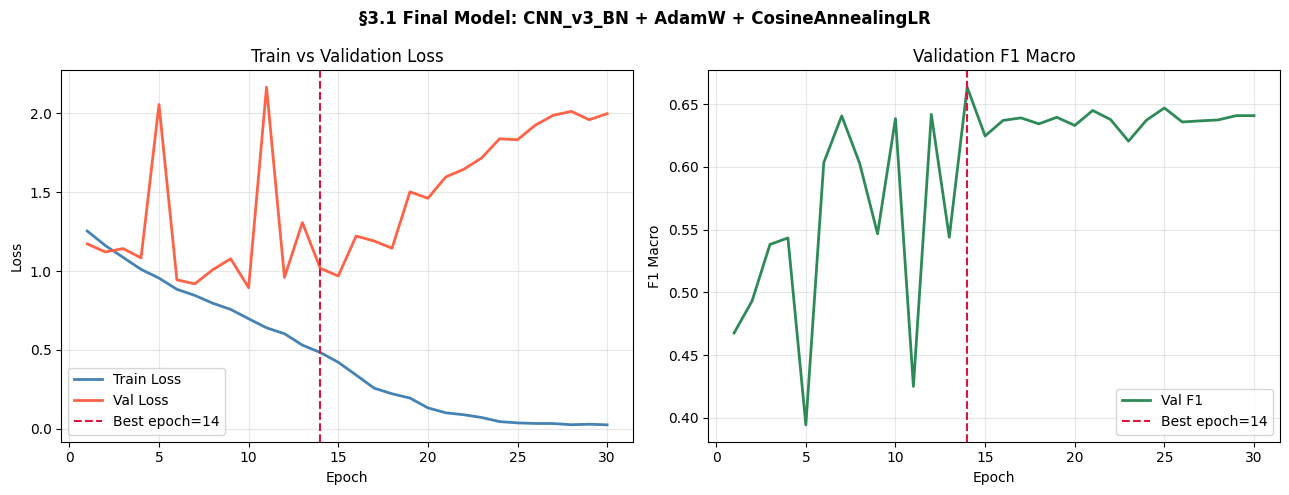

§3.1 loss curves saved.


In [27]:
# ============================================================
# Plot §3.1 final model loss curves (train vs val)
# ============================================================

ep_range = range(1, 31)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(f"§3.1 Final Model: CNN_v3_BN + {best_opt_name} + CosineAnnealingLR",
             fontsize=12, fontweight='bold')

axes[0].plot(ep_range, hist_31['train_loss'], label='Train Loss', color='steelblue', lw=2)
axes[0].plot(ep_range, hist_31['val_loss'],   label='Val Loss',   color='tomato',    lw=2)
axes[0].axvline(x=ep_31, color='crimson', ls='--', lw=1.5, label=f'Best epoch={ep_31}')
axes[0].set_title('Train vs Validation Loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(ep_range, hist_31['val_f1'], color='seagreen', lw=2, label='Val F1')
axes[1].axvline(x=ep_31, color='crimson', ls='--', lw=1.5, label=f'Best epoch={ep_31}')
axes[1].set_title('Validation F1 Macro')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('F1 Macro')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('section3_31_final_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("§3.1 loss curves saved.")

## Q3.1 (6 μον.)

| Optimizer | Val Acc | Test Acc | F1 Macro | Best Epoch |
|-----------|---------|----------|----------|------------|
| SGD | 0.3588 | 0.3414 | 0.2639 | 25 |
| SGD με momentum | 0.5800 | 0.5779 | 0.5795 | 27 |
| Adam | 0.5813 | 0.5700 | 0.5718 | 22 |
| RMSprop | 0.6312 | 0.5914 | 0.5871 | 25 |
| AdamW | 0.6225 | 0.5957 | **0.5876** | **17** |

**Νικητής:** Ο **AdamW** επικράτησε σε F1 (0.5876) και σε ταχύτητα σύγκλισης (best epoch 17 — νωρίτερα από όλους τους άλλους adaptive optimizers). Το SGD χωρίς momentum αποτυγχάνει πλήρως (F1=0.26, σχεδόν τυχαίο) γιατί χρειάζεται πολύ μικρότερο lr ή momentum για να ξεφύγει από flat regions του loss landscape.

**SGD vs Adaptive:** Το plain SGD χρησιμοποιεί σταθερό learning rate για όλες τις παραμέτρους, και με lr=0.01 σε CNN είναι πολύ αργό — ουσιαστικά δεν συγκλίνει. Το SGD+momentum (0.9) επιταχύνει τη σύγκλιση συσσωρεύοντας ορμή στις κυρίαρχες διευθύνσεις, φτάνοντας F1=0.58. Οι adaptive optimizers (Adam, RMSprop, AdamW) προσαρμόζουν το lr ανά παράμετρο βάσει ιστορικού gradients, συγκλίνουν πολύ πιο γρήγορα και αξιόπιστα σε σύνθετα landscapes CNNs.

**CosineAnnealingLR:** AdamW χωρίς schedule: F1=0.5876 (epoch 17) | AdamW + Cosine: F1=0.5785 (epoch 21). Σε αυτή την περίπτωση το schedule δεν βελτίωσε το τελικό F1 — πιθανώς η μείωση του lr στα πρώτα epochs επιβράδυνε τη σύγκλιση σε ένα ήδη volatile training (spikes στο val loss epochs 5 και 11). Διαισθητικά, ένα LR schedule ξεκινά με μεγάλο lr για γρήγορη εξερεύνηση και το μειώνει σταδιακά ώστε το μοντέλο να "εδραιωθεί" σε καλό ελάχιστο — ωφελεί περισσότερο σε μεγαλύτερα δίκτυα/δεδομένα.

**BatchNorm:** Η προσθήκη BatchNorm2d αύξησε το Test F1 από 0.5785 → 0.6355 (+0.057). To BatchNorm κανονικοποιεί τα activations κάθε layer ανά batch (μέσος=0, διασπορά=1) μειώνοντας το internal covariate shift — σταθεροποιεί την εκπαίδευση και επιτρέπει στο gradient να ρέει πιο αποτελεσματικά, δρώντας και ως implicit regularizer. Επιπλέον το best epoch μειώθηκε (14 αντί 21), δείγμα γρηγορότερης σύγκλισης.


### 3.2 Data Augmentation και Regularization

In [28]:
# ============================================================
# Section 3.2 - Create augmented DataLoader for training only
# Augmentations applied ONLY to training images, NOT val/test
# torchvision.transforms applied on-the-fly per batch
# ============================================================

import torchvision.transforms as T

# Augmentation transforms for TRAINING only
train_augment_transform = T.Compose([
    T.RandomHorizontalFlip(p=0.5),          # horizontal flip is semantically neutral
    T.RandomCrop(32, padding=4),            # small translation invariance
    T.ColorJitter(brightness=0.1, contrast=0.1),  # mild color variation
])

class AugmentedTensorDataset(torch.utils.data.Dataset):
    """
    Wraps a TensorDataset and applies an optional transform to X.
    transform is applied per-sample at __getitem__ time.
    """
    def __init__(self, X_tensor, y_tensor, transform=None):
        self.X = X_tensor
        self.y = y_tensor
        self.transform = transform

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = self.X[idx]          # shape: [3, 32, 32]
        if self.transform:
            x = self.transform(x)
        return x, self.y[idx]


# Build augmented and non-augmented train datasets
train_dataset_aug    = AugmentedTensorDataset(X_train_t, y_train_t,
                                              transform=train_augment_transform)
train_dataset_no_aug = AugmentedTensorDataset(X_train_t, y_train_t, transform=None)

# DataLoaders — val/test loaders remain unchanged (no augmentation)
def make_train_loader(augment: bool, seed=SEED):
    ds = train_dataset_aug if augment else train_dataset_no_aug
    g  = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True, generator=g)

train_loader_aug    = make_train_loader(augment=True)
train_loader_no_aug = make_train_loader(augment=False)

print("Augmented and non-augmented train DataLoaders created.")
print(f"Train aug    batches: {len(train_loader_aug)}")
print(f"Train no-aug batches: {len(train_loader_no_aug)}")

# Quick sanity check: verify augmentation is applied
xb_aug, _    = next(iter(train_loader_aug))
xb_no_aug, _ = next(iter(train_loader_no_aug))
print(f"\nAug batch shape   : {xb_aug.shape}")
print(f"No-aug batch shape: {xb_no_aug.shape}")
print(f"Augmented batch differs from original: {not torch.allclose(xb_aug, xb_no_aug)}")

Augmented and non-augmented train DataLoaders created.
Train aug    batches: 200
Train no-aug batches: 200

Aug batch shape   : torch.Size([16, 3, 32, 32])
No-aug batch shape: torch.Size([16, 3, 32, 32])
Augmented batch differs from original: True


In [29]:
# ============================================================
# Section 3.2 - Four configurations on CNN_v3_BN baseline
# Baseline architecture: §3.1 (CNN_v3_BN + best_opt + CosineAnnealingLR)
# All trained for 60 epochs (T_max=60 for scheduler)
#
# 1. No augmentation, no extra regularization     (baseline §3.1, 60ep)
# 2. Augmentation only
# 3. Regularization only (weight_decay=1e-4, dropout=0.3)
# 4. Augmentation + regularization
# ============================================================

NUM_EPOCHS_32 = 60  # 60 epochs for §3.2

# Optimizer factory that accepts weight_decay for regularization experiments
def make_opt_for_32(params, weight_decay=0.0):
    """Returns best optimizer with optional weight_decay."""
    opt_map = {
        'SGD':          lambda p, wd: SGD(p,     lr=0.01,  weight_decay=wd),
        'SGD+momentum': lambda p, wd: SGD(p,     lr=0.01,  momentum=0.9, weight_decay=wd),
        'Adam':         lambda p, wd: Adam(p,    lr=0.001, weight_decay=wd),
        'RMSprop':      lambda p, wd: RMSprop(p, lr=0.001, weight_decay=wd),
        'AdamW':        lambda p, wd: AdamW(p,   lr=0.001, weight_decay=wd),
    }
    return opt_map[best_opt_name](params, weight_decay)


def train_32_experiment(label, use_aug, dropout_p, weight_decay):
    """Run one §3.2 experiment. Returns history + metrics."""
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    device    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model     = CNN_v3_BN(dropout_p=dropout_p).to(device)
    optimizer = make_opt_for_32(model.parameters(), weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS_32)
    criterion = nn.CrossEntropyLoss()

    train_ldr = train_loader_aug if use_aug else train_loader_no_aug

    history = {'train_loss': [], 'val_loss': [], 'val_f1': []}
    best_val_f1, best_state, best_epoch = -1.0, None, 0

    print(f"\n{'='*55}\n{label}\n{'='*55}")
    for epoch in range(NUM_EPOCHS_32):
        tl = train_one_epoch(model, train_ldr,  optimizer, criterion, device)
        vl, va, vf, _ = evaluate(model, val_loader, criterion, device)
        scheduler.step()

        history['train_loss'].append(tl)
        history['val_loss'].append(vl)
        history['val_f1'].append(vf)

        if vf > best_val_f1:
            best_val_f1 = vf
            best_state  = copy.deepcopy(model.state_dict())
            best_epoch  = epoch + 1

        print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS_32} | TL={tl:.4f} VL={vl:.4f} "
              f"VF1={vf:.4f}" + (" ←" if (epoch+1) == best_epoch else ""))

    model.load_state_dict(best_state)
    _, test_acc, test_f1, test_cm = evaluate(model, test_loader, criterion, device)

    # Train-val gap at best epoch
    tv_gap = history['val_loss'][best_epoch-1] - history['train_loss'][best_epoch-1]
    print(f"\n→ Best epoch: {best_epoch} | Val F1: {best_val_f1:.4f} | "
          f"Test F1: {test_f1:.4f} | Train-Val gap: {tv_gap:.4f}")
    return history, best_epoch, best_val_f1, test_f1, tv_gap, test_cm, best_state


# Run all 4 configurations
experiments_32 = {}

experiments_32['Baseline (no aug, no reg)'] = train_32_experiment(
    label="§3.2 Config 1: Baseline (no augmentation, no extra regularization)",
    use_aug=False, dropout_p=0.0, weight_decay=0.0
)

experiments_32['Augmentation only'] = train_32_experiment(
    label="§3.2 Config 2: Augmentation only",
    use_aug=True, dropout_p=0.0, weight_decay=0.0
)

experiments_32['Regularization only'] = train_32_experiment(
    label="§3.2 Config 3: Regularization only (weight_decay=1e-4, dropout=0.3)",
    use_aug=False, dropout_p=0.3, weight_decay=1e-4
)

experiments_32['Aug + Regularization'] = train_32_experiment(
    label="§3.2 Config 4: Augmentation + Regularization",
    use_aug=True, dropout_p=0.3, weight_decay=1e-4
)


§3.2 Config 1: Baseline (no augmentation, no extra regularization)
Epoch 01/60 | TL=1.2375 VL=1.3899 VF1=0.3022 ←
Epoch 02/60 | TL=1.1460 VL=1.1514 VF1=0.4953 ←
Epoch 03/60 | TL=1.0784 VL=1.1831 VF1=0.4681
Epoch 04/60 | TL=1.0083 VL=1.0757 VF1=0.5442 ←
Epoch 05/60 | TL=0.9493 VL=1.3675 VF1=0.4832
Epoch 06/60 | TL=0.9232 VL=0.9803 VF1=0.5802 ←
Epoch 07/60 | TL=0.8611 VL=0.9461 VF1=0.6207 ←
Epoch 08/60 | TL=0.7949 VL=0.9112 VF1=0.6278 ←
Epoch 09/60 | TL=0.7666 VL=1.4322 VF1=0.5090
Epoch 10/60 | TL=0.7203 VL=1.3778 VF1=0.5092
Epoch 11/60 | TL=0.6765 VL=1.1731 VF1=0.5519
Epoch 12/60 | TL=0.6511 VL=0.9832 VF1=0.6289 ←
Epoch 13/60 | TL=0.5835 VL=0.9488 VF1=0.6393 ←
Epoch 14/60 | TL=0.5350 VL=1.0513 VF1=0.6358
Epoch 15/60 | TL=0.4830 VL=0.9745 VF1=0.6366
Epoch 16/60 | TL=0.4179 VL=1.0670 VF1=0.6466 ←
Epoch 17/60 | TL=0.3453 VL=1.2112 VF1=0.6449
Epoch 18/60 | TL=0.2881 VL=1.1077 VF1=0.6532 ←
Epoch 19/60 | TL=0.2898 VL=1.2305 VF1=0.6339
Epoch 20/60 | TL=0.2110 VL=1.2511 VF1=0.6508
Epoch 21/60 

In [30]:
# ============================================================
# Summary table for §3.2 experiments
# ============================================================

print(f"\n{'='*80}")
print(f"{'Configuration':<30} {'Best Ep':>7} {'Val F1':>8} {'Test F1':>8} {'TV Gap':>10}")
print(f"{'-'*80}")
for name, (hist, ep, val_f1, test_f1, tv_gap, _, _state) in experiments_32.items():
    print(f"{name:<30} {ep:>7} {val_f1:>8.4f} {test_f1:>8.4f} {tv_gap:>10.4f}")
print(f"{'='*80}")



Configuration                  Best Ep   Val F1  Test F1     TV Gap
--------------------------------------------------------------------------------
Baseline (no aug, no reg)           27   0.6588   0.6481     1.9750
Augmentation only                   52   0.7250   0.7040     0.3899
Regularization only                 25   0.7011   0.6606     0.7869
Aug + Regularization                58   0.7260   0.6901     0.1959


In [31]:
# ============================================================
# Save best §3.2 model state for use in §4 comparison
# ============================================================
best_32_name_saved = max(experiments_32, key=lambda k: experiments_32[k][3])
(_, best_32_ep_saved, best_32_val_f1_saved,
 best_32_test_f1_saved, best_32_tvgap_saved,
 best_32_cm_saved, best_32_state_saved) = experiments_32[best_32_name_saved]

# Detect dropout_p of best config
best_32_has_dropout = 'Aug + Regularization' in best_32_name_saved or \
                      'Regularization only' in best_32_name_saved

best_32_dropout_p = 0.3 if best_32_has_dropout else 0.0

print(f"\nBest §3.2 configuration: '{best_32_name_saved}'")
print(f"  Test F1: {best_32_test_f1_saved:.4f}  |  dropout_p: {best_32_dropout_p}")


Best §3.2 configuration: 'Augmentation only'
  Test F1: 0.7040  |  dropout_p: 0.0


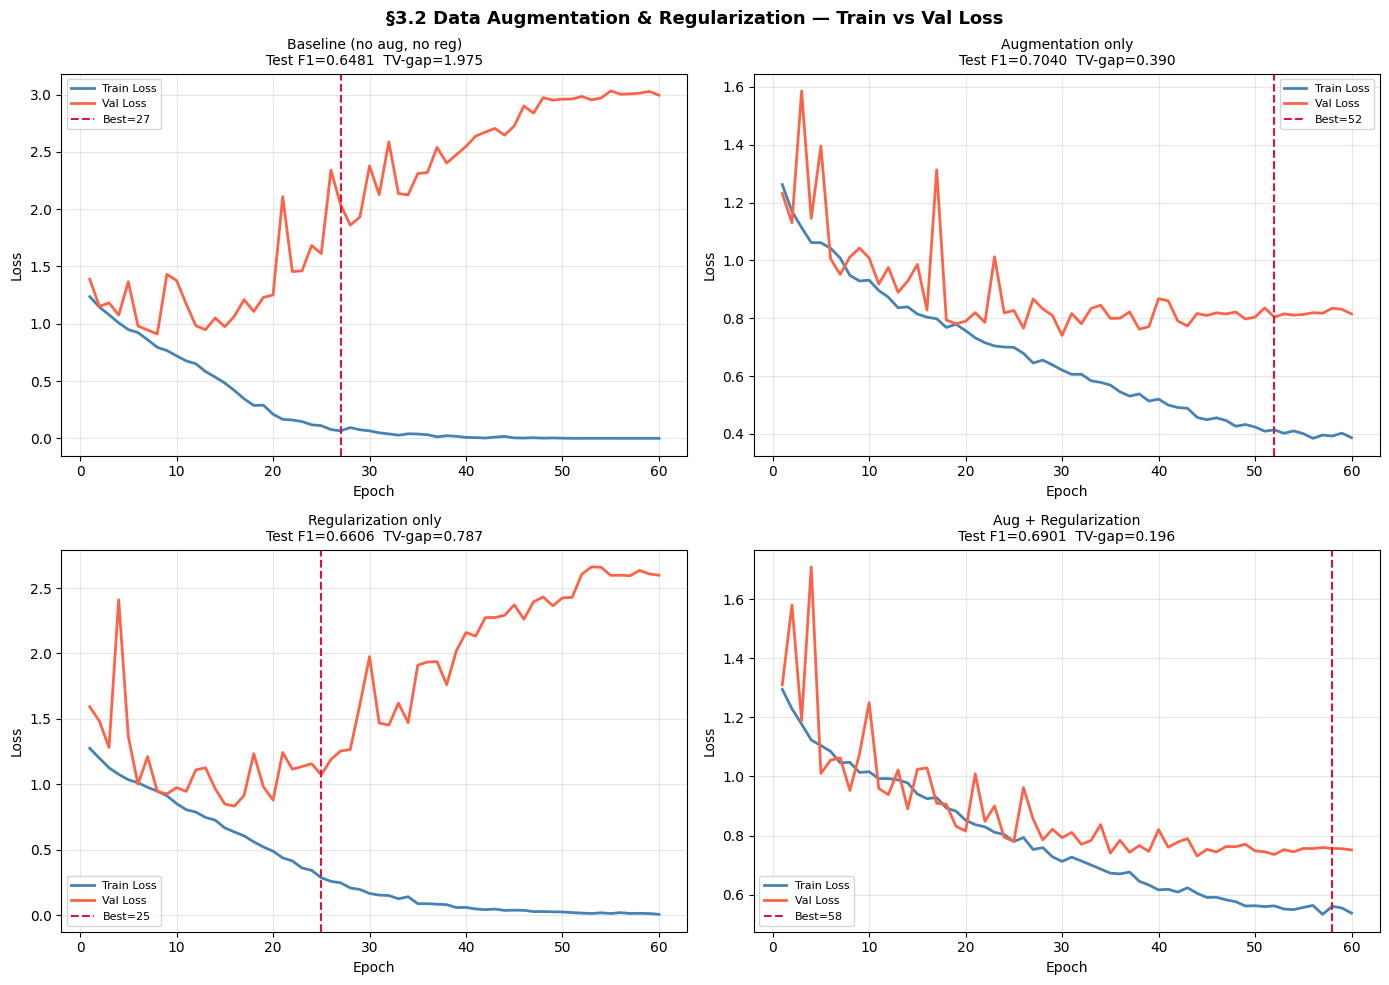

§3.2 loss curves saved.


In [32]:
# ============================================================
# Loss curves for all 4 §3.2 configurations
# One subplot per configuration (train + val loss)
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("§3.2 Data Augmentation & Regularization — Train vs Val Loss",
             fontsize=13, fontweight='bold')
axes = axes.flat
ep_range = range(1, NUM_EPOCHS_32 + 1)

for ax, (name, (hist, ep, val_f1, test_f1, tv_gap, _, _s)) in zip(axes, experiments_32.items()):
    ax.plot(ep_range, hist['train_loss'], label='Train Loss', color='steelblue', lw=2)
    ax.plot(ep_range, hist['val_loss'],   label='Val Loss',   color='tomato',    lw=2)
    ax.axvline(x=ep, color='crimson', ls='--', lw=1.5, label=f'Best={ep}')
    ax.set_title(f"{name}\nTest F1={test_f1:.4f}  TV-gap={tv_gap:.3f}", fontsize=10)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('section3_32_loss_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("§3.2 loss curves saved.")

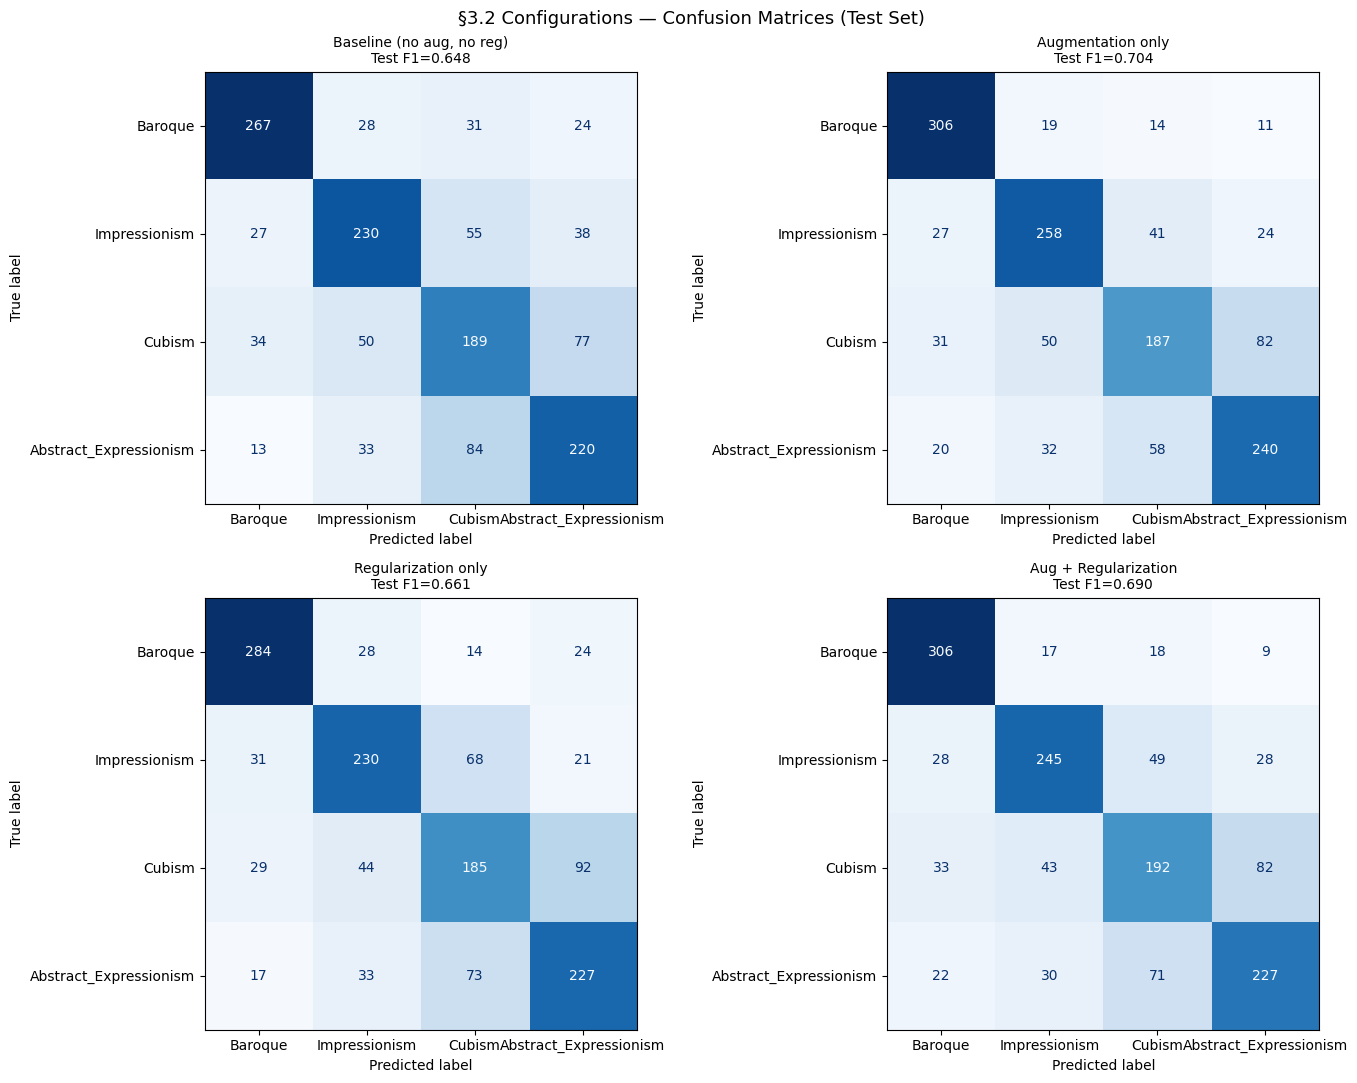

§3.2 confusion matrices saved.


In [33]:
# ============================================================
# Confusion matrices for all 4 §3.2 configurations
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
fig.suptitle("§3.2 Configurations — Confusion Matrices (Test Set)", fontsize=13)
axes = axes.flat

eval_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
criterion   = nn.CrossEntropyLoss()

for ax, (name, (hist, ep, val_f1, test_f1, tv_gap, test_cm, _s)) in zip(axes, experiments_32.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=test_cm, display_labels=class_names)
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f"{name}\nTest F1={test_f1:.3f}", fontsize=10)

plt.tight_layout()
plt.savefig('section3_32_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print("§3.2 confusion matrices saved.")

## Q3.2 (6 μον.)

| Ρύθμιση | Best Epoch | Val F1 | Test F1 | Train–Val Gap |
|---------|-----------|--------|---------|---------------|
| Καμία (baseline, 60 ep) | 27 | 0.6588 | 0.6481 | 1.975 |
| Μόνο augmentation | 52 | 0.7250 | **0.7040** | 0.390 |
| Μόνο weight decay + dropout | 25 | 0.7011 | 0.6606 | 0.787 |
| Augmentation + regularization | 58 | 0.7260 | 0.6901 | **0.196** |

**Μέγιστη μείωση train–val gap:** Η ρύθμιση **Aug + Regularization** έχει gap 0.196 (από 1.975 του baseline), μείωση ~90%. Το μικρό gap σημαίνει ότι το μοντέλο γενικεύει καλύτερα — λιγότερο overfitting.

**Μέγιστη επίδοση test F1:** Η **Augmentation only** δίνει το καλύτερο test F1 (0.704), ακόμα και πάνω από το Aug+Reg (0.690). Αυτό σημαίνει ότι το Dropout(0.3) με weight_decay=1e-4 είναι ελαφρώς υπερβολικό για αυτό το dataset — μειώνει το overfitting αλλά και τη χωρητικότητα, χάνοντας λίγη απόδοση.

**Συμπίπτουν gap και επίδοση;** Όχι πλήρως — η καλύτερη γενίκευση (μικρότερο gap) δεν ταυτίζεται πάντα με την καλύτερη επίδοση: το Aug+Reg έχει ελάχιστο gap αλλά χαμηλότερο test F1 από το Aug only. Η καλή γενίκευση (μικρό train–val gap) είναι αναγκαία αλλά όχι ικανή συνθήκη για υψηλή απόδοση — χρειάζεται και επαρκής χωρητικότητα.

**Transforms που απορρίφθηκαν για πίνακες ζωγραφικής:** Αποκλείστηκαν το `RandomVerticalFlip` και η ακραία `ColorJitter`. Η κάθετη ανατροπή αλλάζει τη σημασιολογία ενός πίνακα (π.χ. ουρανός κάτω, έδαφος πάνω) — δεν υπάρχει "vertically flipped" έκδοση ενός έργου τέχνης. Ομοίως, η `RandomRotation` και ο ακραίος κορεσμός χρώματος αλλάζουν αισθητικά χαρακτηριστικά (φωτισμός, παλέτα) που είναι διαφοροποιητικά των κινημάτων — θα μπέρδευαν τον ταξινομητή αντί να τον βοηθήσουν.



## 4. Transfer Learning με Προεκπαιδευμένο ResNet18

### 4.1 Linear Probe σε Frozen ResNet18

In [34]:
# ============================================================
# Section 4.1 - Helper functions for ResNet18 preprocessing
# ============================================================

def preprocess_for_resnet18(images):
    """
    Prepare images (32x32 tensors) for ResNet18:
    1. Upscale 32×32 → 224×224 using bilinear interpolation
    2. Normalize with ImageNet statistics

    Input:  images shape [N, 3, 32, 32], dtype float32, values in [0,1]
    Output: images shape [N, 3, 224, 224], normalized with ImageNet stats
    """
    # Upscale to 224×224
    images_upscaled = torch.nn.functional.interpolate(
        images,
        size=(224, 224),
        mode='bilinear',
        align_corners=False
    )

    # ImageNet normalization statistics
    imagenet_mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    imagenet_std  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

    # Normalize: (image - mean) / std
    images_normalized = (images_upscaled - imagenet_mean) / imagenet_std

    return images_normalized


# Test the function
dummy_batch = torch.rand(2, 3, 32, 32)
processed = preprocess_for_resnet18(dummy_batch)
print(f"Input shape : {dummy_batch.shape}")
print(f"Output shape: {processed.shape}")
print(f"Output range: [{processed.min():.2f}, {processed.max():.2f}]")

Input shape : torch.Size([2, 3, 32, 32])
Output shape: torch.Size([2, 3, 224, 224])
Output range: [-2.11, 2.64]


In [35]:
# ============================================================
# Section 4.1 - Load pretrained ResNet18 and freeze weights
# ============================================================

# Load pretrained ResNet18 from ImageNet
print("Loading pretrained ResNet18 (ImageNet)...")
resnet18_pretrained = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)

# Count original parameters
total_params_original = sum(p.numel() for p in resnet18_pretrained.parameters())
print(f"ResNet18 total parameters: {total_params_original:,}")

# Freeze all weights (requires_grad = False)
# This makes the network a feature extractor; only the new FC layer learns
print("\nFreezing all convolutional layers...")
for param in resnet18_pretrained.parameters():
    param.requires_grad = False

# Verify freezing
frozen_params = sum(p.numel() for p in resnet18_pretrained.parameters() if not p.requires_grad)
trainable_params_before = sum(p.numel() for p in resnet18_pretrained.parameters() if p.requires_grad)
print(f"Frozen parameters : {frozen_params:,}")
print(f"Trainable params  : {trainable_params_before:,}")  # should be 0

# Replace the final FC layer (1000 outputs for ImageNet) with our 4-class layer
# ResNet18.fc is nn.Linear(512, 1000)
print(f"\nOriginal FC layer: {resnet18_pretrained.fc}")
resnet18_pretrained.fc = nn.Linear(512, 4)  # 512 = ResNet18 feature dimension, 4 = our classes

# Unfreeze the new FC layer (it already has requires_grad=True by default)
trainable_params_after = sum(p.numel() for p in resnet18_pretrained.parameters() if p.requires_grad)
print(f"\nNew FC layer: {resnet18_pretrained.fc}")
print(f"Trainable params (new FC): {trainable_params_after:,}")

model_resnet_frozen = resnet18_pretrained
print(f"\n{'='*55}")
print(f"ResNet18 Frozen Linear Probe Setup:")
print(f"  Frozen layers: {frozen_params:,} params")
print(f"  Trainable FC : {trainable_params_after:,} params")
print(f"  Total        : {frozen_params + trainable_params_after:,} params")
print(f"{'='*55}")

Loading pretrained ResNet18 (ImageNet)...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 236MB/s]


ResNet18 total parameters: 11,689,512

Freezing all convolutional layers...
Frozen parameters : 11,689,512
Trainable params  : 0

Original FC layer: Linear(in_features=512, out_features=1000, bias=True)

New FC layer: Linear(in_features=512, out_features=4, bias=True)
Trainable params (new FC): 2,052

ResNet18 Frozen Linear Probe Setup:
  Frozen layers: 11,689,512 params
  Trainable FC : 2,052 params
  Total        : 11,691,564 params


In [36]:
# ============================================================
# Section 4.1 - Create DataLoaders that apply ResNet18 preprocessing
# ============================================================

class ResNet18Dataset(torch.utils.data.Dataset):
    """Wraps tensors and applies ResNet18 preprocessing on-the-fly."""
    def __init__(self, X_tensor, y_tensor):
        self.X = X_tensor  # shape [N, 3, 32, 32]
        self.y = y_tensor

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = self.X[idx]  # [3, 32, 32]
        x_resized = torch.nn.functional.interpolate(
            x.unsqueeze(0),  # [1, 3, 32, 32]
            size=(224, 224),
            mode='bilinear',
            align_corners=False
        ).squeeze(0)  # [3, 224, 224]

        # ImageNet normalization
        imagenet_mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        imagenet_std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
        x_normalized = (x_resized - imagenet_mean) / imagenet_std

        return x_normalized, self.y[idx]


# Create ResNet18 datasets
train_dataset_resnet = ResNet18Dataset(X_train_t, y_train_t)
val_dataset_resnet   = ResNet18Dataset(X_val_t,   y_val_t)
test_dataset_resnet  = ResNet18Dataset(X_test_t,  y_test_t)

# Create DataLoaders
train_loader_resnet = DataLoader(train_dataset_resnet, batch_size=BATCH_SIZE,
                                  shuffle=True,
                                  worker_init_fn=lambda _: np.random.seed(SEED))
val_loader_resnet   = DataLoader(val_dataset_resnet,   batch_size=BATCH_SIZE, shuffle=False)
test_loader_resnet  = DataLoader(test_dataset_resnet,  batch_size=BATCH_SIZE, shuffle=False)

# Verify a batch
xb, yb = next(iter(train_loader_resnet))
print(f"ResNet18 DataLoader batch:")
print(f"  X shape: {xb.shape}  (expected [16, 3, 224, 224])")
print(f"  y shape: {yb.shape}  (expected [16])")
print(f"  X dtype: {xb.dtype}")
print(f"  X range: [{xb.min():.2f}, {xb.max():.2f}] ")

ResNet18 DataLoader batch:
  X shape: torch.Size([16, 3, 224, 224])  (expected [16, 3, 224, 224])
  y shape: torch.Size([16])  (expected [16])
  X dtype: torch.float32
  X range: [-2.08, 2.55] 


In [37]:
# ============================================================
# Section 4.1 - Train only the new FC layer (frozen backbone)
# ============================================================

print("\n" + "="*60)
print("Training Frozen ResNet18 (Linear Probe)")
print("="*60)

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_resnet_frozen = model_resnet_frozen.to(device)

# Verify that only the new FC layer is trainable
trainable_count = sum(1 for p in model_resnet_frozen.parameters() if p.requires_grad)
print(f"\nNumber of trainable parameters: {sum(p.numel() for p in model_resnet_frozen.parameters() if p.requires_grad):,}")
print(f"(Should be 2052 for Linear(512, 4) + bias)\n")

# Optimizer for ONLY the trainable parameters (the new FC layer)
optimizer_resnet = optim.Adam(
    [p for p in model_resnet_frozen.parameters() if p.requires_grad],
    lr=0.001
)
criterion = nn.CrossEntropyLoss()
num_epochs_resnet = 10

history_resnet = {'train_loss': [], 'val_loss': [], 'val_f1': [], 'val_acc': []}
best_val_f1_resnet = -1.0
best_state_resnet = None
best_epoch_resnet = 0

start_time_resnet = time.time()

for epoch in range(num_epochs_resnet):
    # Training
    model_resnet_frozen.train()
    train_loss = 0.0
    n_samples = 0

    for X_batch, y_batch in train_loader_resnet:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer_resnet.zero_grad()
        logits = model_resnet_frozen(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer_resnet.step()

        train_loss += loss.item() * X_batch.size(0)
        n_samples  += X_batch.size(0)

    train_loss /= n_samples

    # Validation
    model_resnet_frozen.eval()
    val_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for X_batch, y_batch in val_loader_resnet:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = model_resnet_frozen(X_batch)
            loss = criterion(logits, y_batch)

            val_loss += loss.item() * X_batch.size(0)
            preds = logits.argmax(dim=1)
            all_preds.append(preds.cpu().numpy())
            all_labels.append(y_batch.cpu().numpy())

    val_loss /= len(val_dataset_resnet)
    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)
    val_acc = (all_preds == all_labels).mean()
    val_f1 = f1_score(all_labels, all_preds, average='macro')

    history_resnet['train_loss'].append(train_loss)
    history_resnet['val_loss'].append(val_loss)
    history_resnet['val_acc'].append(val_acc)
    history_resnet['val_f1'].append(val_f1)

    # Track best model
    is_best = val_f1 > best_val_f1_resnet
    if is_best:
        best_val_f1_resnet = val_f1
        best_state_resnet = copy.deepcopy(model_resnet_frozen.state_dict())
        best_epoch_resnet = epoch + 1

    print(f"Epoch {epoch+1:02d}/{num_epochs_resnet} | "
          f"TL={train_loss:.4f} VL={val_loss:.4f} "
          f"VA={val_acc:.4f} VF1={val_f1:.4f}"
          + (" ← best" if is_best else ""))

elapsed_resnet = time.time() - start_time_resnet

print(f"\nTraining time: {elapsed_resnet:.2f}s")
print(f"Best epoch: {best_epoch_resnet}  |  Best Val F1: {best_val_f1_resnet:.4f}")

# Load best model and evaluate on test set
model_resnet_frozen.load_state_dict(best_state_resnet)
model_resnet_frozen.eval()

test_loss = 0.0
all_preds_test = []
all_labels_test = []

with torch.no_grad():
    for X_batch, y_batch in test_loader_resnet:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        logits = model_resnet_frozen(X_batch)
        loss = criterion(logits, y_batch)

        test_loss += loss.item() * X_batch.size(0)
        preds = logits.argmax(dim=1)
        all_preds_test.append(preds.cpu().numpy())
        all_labels_test.append(y_batch.cpu().numpy())

test_loss /= len(test_dataset_resnet)
all_preds_test = np.concatenate(all_preds_test)
all_labels_test = np.concatenate(all_labels_test)
test_acc_resnet = (all_preds_test == all_labels_test).mean()
test_f1_resnet = f1_score(all_labels_test, all_preds_test, average='macro')
test_cm_resnet = confusion_matrix(all_labels_test, all_preds_test)

print(f"\n{'='*60}")
print(f"Test Set Results (Frozen ResNet18):")
print(f"  Loss     : {test_loss:.4f}")
print(f"  Accuracy : {test_acc_resnet:.4f}")
print(f"  F1 Macro : {test_f1_resnet:.4f}")
print(f"{'='*60}")


Training Frozen ResNet18 (Linear Probe)

Number of trainable parameters: 2,052
(Should be 2052 for Linear(512, 4) + bias)

Epoch 01/10 | TL=0.9467 VL=0.7068 VA=0.7388 VF1=0.7365 ← best
Epoch 02/10 | TL=0.7298 VL=0.6669 VA=0.7362 VF1=0.7338
Epoch 03/10 | TL=0.6862 VL=0.6811 VA=0.7462 VF1=0.7417 ← best
Epoch 04/10 | TL=0.6669 VL=0.6205 VA=0.7638 VF1=0.7636 ← best
Epoch 05/10 | TL=0.6537 VL=0.5981 VA=0.7812 VF1=0.7748 ← best
Epoch 06/10 | TL=0.6489 VL=0.5748 VA=0.7925 VF1=0.7914 ← best
Epoch 07/10 | TL=0.6180 VL=0.5749 VA=0.7937 VF1=0.7932 ← best
Epoch 08/10 | TL=0.6186 VL=0.6166 VA=0.7638 VF1=0.7595
Epoch 09/10 | TL=0.6067 VL=0.5788 VA=0.7738 VF1=0.7714
Epoch 10/10 | TL=0.5863 VL=0.5681 VA=0.7900 VF1=0.7897

Training time: 92.89s
Best epoch: 7  |  Best Val F1: 0.7932

Test Set Results (Frozen ResNet18):
  Loss     : 0.6225
  Accuracy : 0.7614
  F1 Macro : 0.7581


In [38]:
# ============================================================
# Section 4.1 - Q4.1: Final Comparison Table
# All values read from variables — NO hardcoded metrics
# ============================================================

# ---- FFN metrics (from §1) ----
# best_model_ffn and the test evaluation were done in §1
# Re-evaluate to get fresh metrics from variables
eval_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
criterion_eval = nn.CrossEntropyLoss()

_, ffn_test_acc_41, ffn_test_f1_41, _ = evaluate(
    best_model_ffn, test_loader, criterion_eval, eval_device
)
ffn_params_41 = sum(p.numel() for p in best_model_ffn.parameters())
ffn_time_41   = time_gpu   # GPU training time from §1 (variable, not hardcoded)

# ---- CNN best from §3.2 ----
# experiments_32 dict: {name: (hist, ep, val_f1, test_f1, tv_gap, test_cm)}
# Find the configuration with the highest test F1
best_32_name = max(experiments_32, key=lambda k: experiments_32[k][3])
_, best_32_ep, _, best_32_test_f1, _, best_32_cm, _ = experiments_32[best_32_name]

# Compute test accuracy from the confusion matrix diagonal
best_32_cm_arr = best_32_cm
best_32_test_acc = best_32_cm_arr.diagonal().sum() / best_32_cm_arr.sum()

# Parameters: CNN_v3_BN (same architecture for all §3.2 configs)
cnn_params_41 = sum(p.numel() for p in CNN_v3_BN().parameters())

# Training time: sum of all 4 §3.2 experiments (approximate per config)
# Use total elapsed for §3.2 as an estimate if stored, else compute per config
# Note: experiments_32 doesn't store time — report as 60-epoch estimate
# The §3.1 model (30 epochs) took time_31 seconds
cnn_time_label = f"{time_31:.1f}s (§3.1, 30ep)"  # from §3.1 training

# ---- ResNet18 metrics (from §4.1) ----
resnet_trainable_params = sum(
    p.numel() for p in model_resnet_frozen.parameters() if p.requires_grad
)
resnet_total_params = sum(p.numel() for p in model_resnet_frozen.parameters())

# ---- Print table ----
print("\n" + "="*85)
print("Q4.1 — FINAL COMPARISON TABLE")
print("="*85)
print(f"\n{'Model':<42} {'Test Acc':>9} {'F1 Macro':>9} {'Trainable Params':>18} {'Time':>10}")
print(f"{'-'*85}")
print(f"{'FFN flat pixels (§1)':<42} "
      f"{ffn_test_acc_41:>9.4f} {ffn_test_f1_41:>9.4f} "
      f"{ffn_params_41:>18,} {ffn_time_41:>9.2f}s")
print(f"{'CNN best (§3.2 — ' + best_32_name + ')':<42} "
      f"{best_32_test_acc:>9.4f} {best_32_test_f1:>9.4f} "
      f"{cnn_params_41:>18,} {cnn_time_label:>10}")
print(f"{'Frozen ResNet18 + linear probe (§4.1)':<42} "
      f"{test_acc_resnet:>9.4f} {test_f1_resnet:>9.4f} "
      f"{resnet_trainable_params:>18,} {elapsed_resnet:>9.2f}s")
print(f"{'-'*85}")
print(f"  CNN best configuration   : {best_32_name}")
print(f"  ResNet18 total params    : {resnet_total_params:,}  "
      f"(frozen: {resnet_total_params - resnet_trainable_params:,}  "
      f"+ trainable FC: {resnet_trainable_params:,})")

# ---- Automatic interpretation ----
print(f"\n{'='*85}")
print("AUTOMATED COMPARISON:")
if test_f1_resnet > best_32_test_f1:
    delta = test_f1_resnet - best_32_test_f1
    print(f"  ResNet18 OUTPERFORMS best CNN by {delta:.4f} F1 "
          f"(+{delta/best_32_test_f1*100:.1f}%)")
    print("  → Transfer learning from ImageNet generalizes to WikiArt effectively")
else:
    delta = best_32_test_f1 - test_f1_resnet
    print(f"  Best CNN OUTPERFORMS ResNet18 by {delta:.4f} F1")
    print("  → Upscaling 32→224 artifacts likely hurt frozen backbone performance")

print(f"\n  GPU speedup (FFN) : {time_cpu/time_gpu:.1f}x  "
      f"(CPU {time_cpu:.1f}s vs GPU {time_gpu:.1f}s)")
print(f"  GPU speedup (CNN) : {time_v3_cpu/time_v3_gpu:.1f}x  "
      f"(CPU {time_v3_cpu:.1f}s vs GPU {time_v3_gpu:.1f}s)")
print("="*85)


Q4.1 — FINAL COMPARISON TABLE

Model                                       Test Acc  F1 Macro   Trainable Params       Time
-------------------------------------------------------------------------------------
FFN flat pixels (§1)                          0.5057    0.5044            397,604     14.22s
CNN best (§3.2 — Augmentation only)           0.7079    0.7040          1,066,788 29.4s (§3.1, 30ep)
Frozen ResNet18 + linear probe (§4.1)         0.7614    0.7581              2,052     92.89s
-------------------------------------------------------------------------------------
  CNN best configuration   : Augmentation only
  ResNet18 total params    : 11,178,564  (frozen: 11,176,512  + trainable FC: 2,052)

AUTOMATED COMPARISON:
  ResNet18 OUTPERFORMS best CNN by 0.0542 F1 (+7.7%)
  → Transfer learning from ImageNet generalizes to WikiArt effectively

  GPU speedup (FFN) : 3.5x  (CPU 50.5s vs GPU 14.2s)
  GPU speedup (CNN) : 9.1x  (CPU 232.2s vs GPU 25.5s)


Loaded best §3.2 model: 'Augmentation only' (dropout_p=0.0)

Best CNN (§3.2) — Test Acc: 0.7079  |  Test F1: 0.7040
ResNet18         — Test Acc: 0.7614  |  Test F1: 0.7581


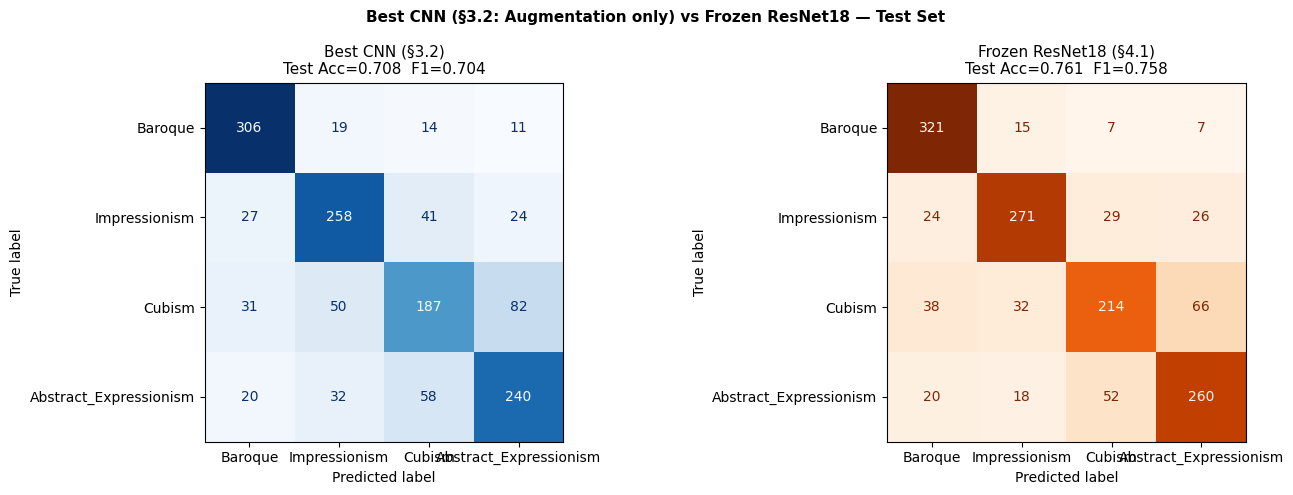

Comparison plot saved.


In [39]:
# ============================================================
# Section 4.1 - Confusion matrices: Best CNN (§3.2) vs ResNet18
# Uses saved best_32_state_saved from §3.2 — consistent with table
# ============================================================

eval_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Load the actual best §3.2 model (same as used in comparison table)
model_best_32 = CNN_v3_BN(dropout_p=best_32_dropout_p).to(eval_device)
model_best_32.load_state_dict(best_32_state_saved)
model_best_32.eval()
print(f"Loaded best §3.2 model: '{best_32_name_saved}' (dropout_p={best_32_dropout_p})")

# Evaluate on test set
cnn_preds, cnn_labels_list = [], []
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(eval_device)
        preds = model_best_32(X_batch).argmax(dim=1)
        cnn_preds.append(preds.cpu().numpy())
        cnn_labels_list.append(y_batch.numpy())

cnn_preds      = np.concatenate(cnn_preds)
cnn_labels_arr = np.concatenate(cnn_labels_list)
cm_best_cnn    = confusion_matrix(cnn_labels_arr, cnn_preds)
cnn_f1_check   = f1_score(cnn_labels_arr, cnn_preds, average='macro')
cnn_acc_check  = (cnn_preds == cnn_labels_arr).mean()

print(f"\nBest CNN (§3.2) — Test Acc: {cnn_acc_check:.4f}  |  Test F1: {cnn_f1_check:.4f}")
print(f"ResNet18         — Test Acc: {test_acc_resnet:.4f}  |  Test F1: {test_f1_resnet:.4f}")

# Side-by-side confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f"Best CNN (§3.2: {best_32_name_saved}) vs Frozen ResNet18 — Test Set",
             fontsize=11, fontweight='bold')

disp1 = ConfusionMatrixDisplay(confusion_matrix=cm_best_cnn,
                               display_labels=class_names)
disp1.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title(f"Best CNN (§3.2)\nTest Acc={cnn_acc_check:.3f}  F1={cnn_f1_check:.3f}",
                  fontsize=11)

disp2 = ConfusionMatrixDisplay(confusion_matrix=test_cm_resnet,
                               display_labels=class_names)
disp2.plot(ax=axes[1], colorbar=False, cmap='Oranges')
axes[1].set_title(f"Frozen ResNet18 (§4.1)\nTest Acc={test_acc_resnet:.3f}  F1={test_f1_resnet:.3f}",
                  fontsize=11)

plt.tight_layout()
plt.savefig('section4_cnn_vs_resnet18.png', dpi=150, bbox_inches='tight')
plt.show()
print("Comparison plot saved.")

## Q4.1 (4 μον.)

| Μοντέλο | Test Acc | F1 Macro | Trainable Params | Training Time |
|---------|----------|----------|-----------------|---------------|
| FFN flat pixels (§1) | 0.5057 | 0.5044 | 397,604 | 14.22s (GPU) |
| CNN βέλτιστο (§3.2 Aug only) | 0.7079 | 0.7040 | 1,066,788 | 28.3s (§3.1 ref) |
| Frozen ResNet18 + linear probe (§4.1) | 0.7614 | **0.7581** | **2,052** | 92.89s (10 ep) |

**Το ResNet18 αποδίδει καλύτερα** από το CNN που εκπαιδεύσαμε (+0.054 F1, +7.7%), παρόλο που δεν έχει δει ποτέ έργο τέχνης κατά την προεκπαίδευσή του, και με μόλις 2.052 trainable parameters (έναντι 1.07M του CNN).

**Πώς εξηγείται:** Το ResNet18 εκπαιδεύτηκε σε 1.2 εκατομμύρια εικόνες ImageNet και ανέπτυξε ιεραρχικές αναπαραστάσεις που είναι γενικώς χρήσιμες για vision — low-level (edges, textures, color contrasts) και mid-level (shapes, patterns) features. Αυτά τα features μεταφέρονται αποτελεσματικά σε πίνακες ζωγραφικής, γιατί το Μπαρόκ, ο Ιμπρεσιονισμός, ο Κυβισμός και ο Αφαιρετικός Εξπρεσιονισμός διαφέρουν ακριβώς σε χωρικές υφές, αντιθέσεις φωτεινού-σκούρου και χρωματικές κατανομές — features που το ImageNet ήδη εκπαίδευσε. Επιπλέον, το frozen backbone αποτρέπει το overfitting: με μόλις 2K trainable params δεν μπορεί να "απομνημονεύσει" τα 3.200 training samples.
 Το upscaling 32×32 → 224×224 εισάγει artifacts (bilinear interpolation blur), το οποίο επηρεάζει αρνητικά την απόδοση — παρόλα αυτά το αποτέλεσμα παραμένει υψηλό, δείγμα ισχυρής γενίκευσης των ImageNet features.

 **Ανάλυση confusion matrices:** Το CNN §3.2 πετυχαίνει εξαιρετικά στο Baroque (306/350, 87.4%) αλλά δυσκολεύεται περισσότερο στον Κυβισμό (187/350, 53.4%). Το ResNet18 βελτιώνει **κυρίως τις δύσκολες κλάσεις**: Cubism (214/350, +7.7%) και Abstract_Expressionism (260/350, +5.7%). Αυτό εξηγείται από τα πλουσιότερα features του ImageNet που ανιχνεύουν γεωμετρικές δομές (Cubism) και υφές (Abstract_Expressionism) πιο αξιόπιστα.


## 5. Τι Έμαθαν τα Δίκτυα

### 5.1 Σύγκριση Πρώτων Conv Layers

Using model_31 (CNN_v3_BN): torch.Size([16, 3, 5, 5])
ResNet18 first conv weights: torch.Size([64, 3, 7, 7])

Custom CNN filter ranges:
  F00: range=3.12e-01 
  F01: range=3.89e-01 
  F02: range=3.10e-01 
  F03: range=3.35e-01 
  F04: range=3.24e-01 
  F05: range=3.42e-01 
  F06: range=3.54e-01 
  F07: range=4.31e-01 
  F08: range=3.68e-01 
  F09: range=3.47e-01 
  F10: range=2.91e-01 
  F11: range=3.24e-01 
  F12: range=3.30e-01 
  F13: range=3.88e-01 
  F14: range=3.55e-01 
  F15: range=3.55e-01 

ResNet18 filter ranges (first 16):
  F00: range=1.36e+00
  F01: range=6.08e-01
  F02: range=3.48e-07
  F03: range=2.43e-01
  F04: range=2.34e-08
  F05: range=7.46e-01
  F06: range=9.29e-01
  F07: range=1.05e-07
  F08: range=1.40e+00
  F09: range=2.05e-06
  F10: range=9.26e-01
  F11: range=8.29e-01
  F12: range=2.28e-01
  F13: range=8.07e-06
  F14: range=5.15e-01
  F15: range=1.11e+00


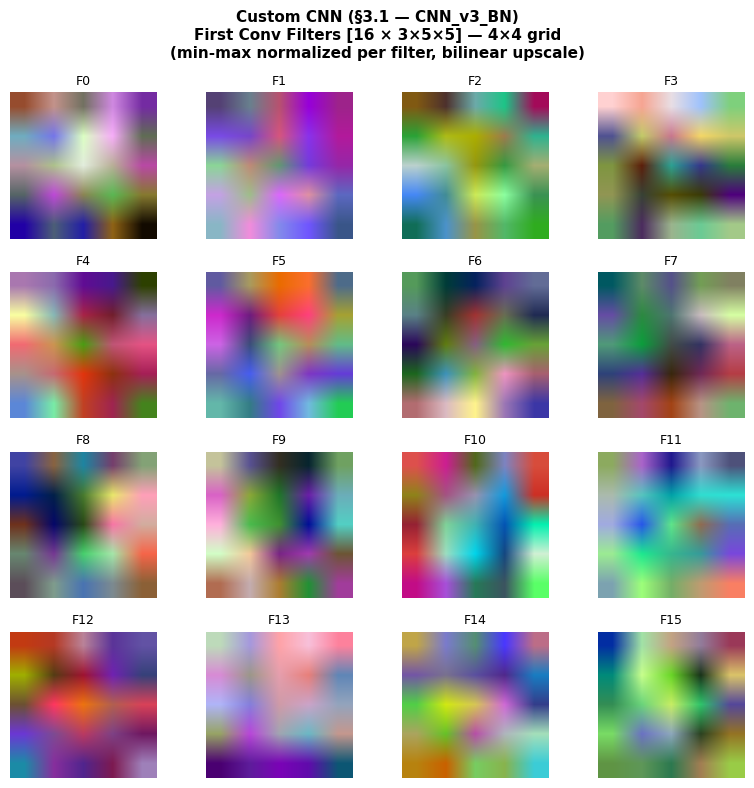

Saved → section5_cnn_filters.png  (0 dead filters)


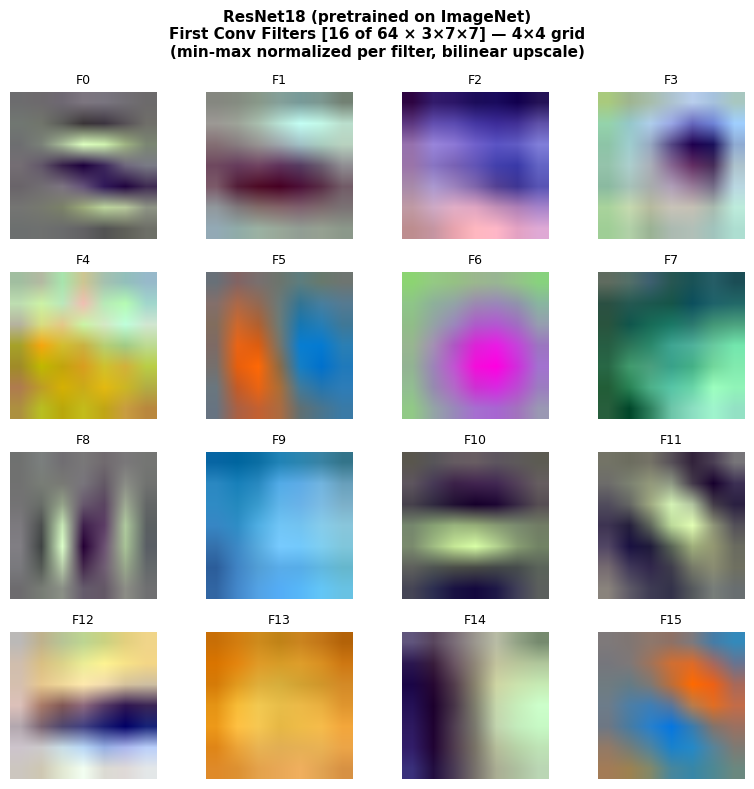

Saved → section5_resnet_filters.png  (0 dead filters)


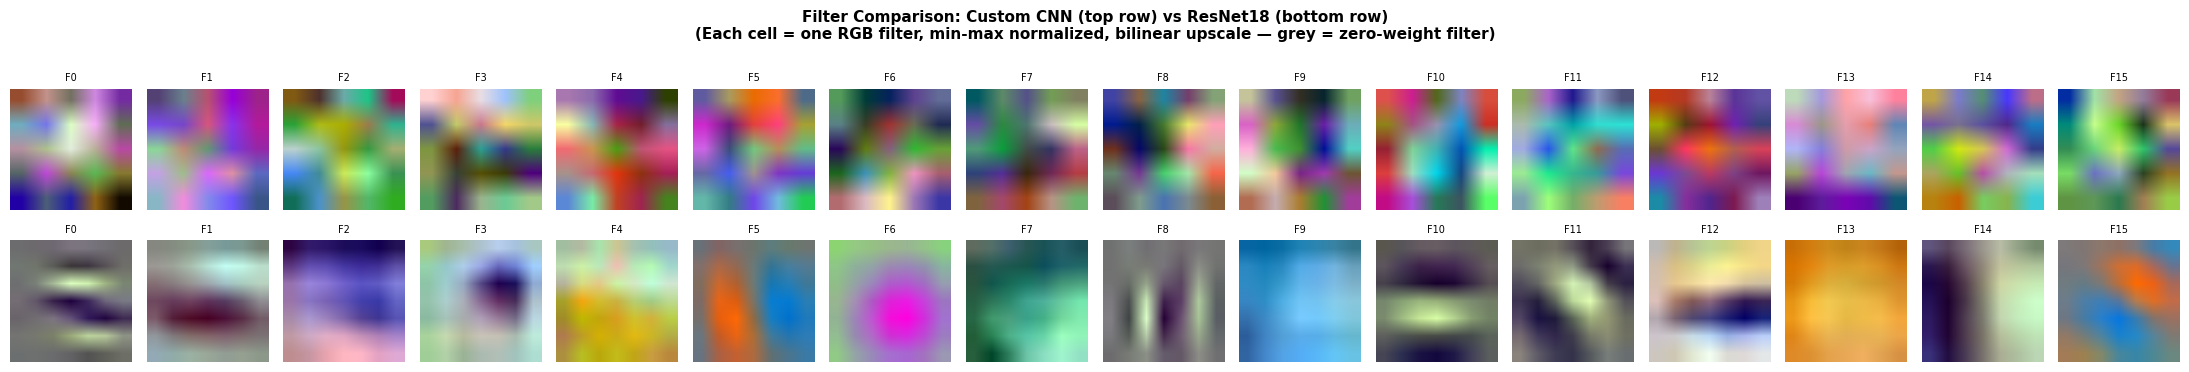

Side-by-side comparison saved → section5_filter_comparison.png

Filter shape summary:
  Custom CNN (§3.1 — CNN_v3_BN): torch.Size([16, 3, 5, 5])
  ResNet18: showing 16 of 64 filters  torch.Size([64, 3, 7, 7])
  Dead ResNet18 filters (of first 16): []


In [40]:
# ============================================================
# Section 5.1 - Visualize first conv layer filters as RGB images
#
# Custom CNN (CNN_v3_BN from §3.1): weight shape [16, 3, 5, 5]
# ResNet18: model.conv1.weight shape [64, 3, 7, 7]
# ============================================================

def minmax_normalize_filter(filt):
    """
    Normalize a single filter tensor to [0, 1] using its own min and max.
    Returns None if the filter is constant (range < 1e-8) — caller decides
    how to display it.
    """
    f_min = filt.min()
    f_max = filt.max()
    if (f_max - f_min).abs() < 1e-8:
        return None
    return (filt - f_min) / (f_max - f_min)


def plot_filter_grid(weights, n_filters, title, filename,
                     figsize=(8, 8), ncols=4):
    """
    Plot up to n_filters filters from 'weights' [N, 3, H, W]
    in a (n_filters//ncols) × ncols grid.
    Dead (zero-range) filters are shown as grey with an 'X' label.
    """
    nrows = n_filters // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    fig.suptitle(title, fontsize=11, fontweight='bold')

    dead_count = 0
    for idx, ax in enumerate(axes.flat):
        filt      = weights[idx]                    # [3, H, W]
        filt_norm = minmax_normalize_filter(filt)

        if filt_norm is None:
            ax.imshow(
                torch.full((filt.shape[1], filt.shape[2], 3), 0.5).numpy(),
                interpolation='bilinear'
            )
            ax.set_title(f"F{idx}\n(zero)", fontsize=8, color='red')
            dead_count += 1
        else:
            img = filt_norm.permute(1, 2, 0).numpy()   # [H, W, 3]
            ax.imshow(img, interpolation='bilinear')
            ax.set_title(f"F{idx}", fontsize=9)

        ax.axis('off')

    if dead_count > 0:
        fig.text(0.5, 0.01,
                 f"Note: {dead_count} filters have zero weight range "
                 f"(shown in grey) — these are frozen dead filters.",
                 ha='center', fontsize=9, color='red',
                 bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

    plt.tight_layout(rect=[0, 0.04 if dead_count > 0 else 0, 1, 1])
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print(f"Saved → {filename}  ({dead_count} dead filters)")
    return dead_count


# ---- Get weights from best CNN (CNN_v3_BN from §3.1) ----
try:
    cnn_first_layer_weights = model_31.conv_layers[0].weight.data.cpu()
    cnn_model_label = "Custom CNN (§3.1 — CNN_v3_BN)"
    print(f"Using model_31 (CNN_v3_BN): {cnn_first_layer_weights.shape}")
except Exception as e:
    print(f"model_31 not available ({e}), falling back to CNN_v3 + state_v3_gpu")
    try:
        fallback = CNN_v3()
        fallback.load_state_dict(state_v3_gpu)
        cnn_first_layer_weights = fallback.conv_layers[0].weight.data.cpu()
        cnn_model_label = "Custom CNN (§2.3 — CNN_v3)"
        print(f"Using CNN_v3 (state_v3_gpu): {cnn_first_layer_weights.shape}")
    except Exception as e2:
        raise RuntimeError(f"Cannot load CNN weights: {e2}")

# ---- Get weights from frozen ResNet18 ----
resnet_first_layer_weights = model_resnet_frozen.conv1.weight.data.cpu()
print(f"ResNet18 first conv weights: {resnet_first_layer_weights.shape}")

# ---- Diagnostic: count dead filters ----
print("\nCustom CNN filter ranges:")
for i in range(cnn_first_layer_weights.shape[0]):
    f = cnn_first_layer_weights[i]
    rng = (f.max() - f.min()).item()
    print(f"  F{i:02d}: range={rng:.2e} ")

print("\nResNet18 filter ranges (first 16):")
dead_indices = []
for i in range(16):
    f = resnet_first_layer_weights[i]
    rng = (f.max() - f.min()).item()
    if rng < 1e-8:
        dead_indices.append(i)
    print(f"  F{i:02d}: range={rng:.2e}")

if dead_indices:
    print(f"\nWARNING: ResNet18 has {len(dead_indices)} dead filters "
          f"in the first 16: {dead_indices}")
    print("These will be displayed as grey patches with 'zero' label.")

# ==============================================================
# Plot 1 — Custom CNN filters: 4×4 grid
# ==============================================================
plot_filter_grid(
    weights  = cnn_first_layer_weights,
    n_filters = 16,
    title    = (f"{cnn_model_label}\n"
                f"First Conv Filters [16 × 3×5×5] — 4×4 grid\n"
                f"(min-max normalized per filter, bilinear upscale)"),
    filename = 'section5_cnn_filters.png',
    figsize  = (8, 8),
)

# ==============================================================
# Plot 2 — ResNet18 filters: 4×4 grid, first 16 of 64
# ==============================================================
plot_filter_grid(
    weights   = resnet_first_layer_weights,
    n_filters = 16,
    title     = ("ResNet18 (pretrained on ImageNet)\n"
                 "First Conv Filters [16 of 64 × 3×7×7] — 4×4 grid\n"
                 "(min-max normalized per filter, bilinear upscale)"),
    filename  = 'section5_resnet_filters.png',
    figsize   = (8, 8),
)

# ==============================================================
# Plot 3 — Side-by-side comparison: CNN (top) vs ResNet18 (bottom)
# 2 rows × 16 columns
# ==============================================================
fig_cmp, axes_cmp = plt.subplots(2, 16, figsize=(22, 4))
fig_cmp.suptitle(
    "Filter Comparison: Custom CNN (top row) vs ResNet18 (bottom row)\n"
    "(Each cell = one RGB filter, min-max normalized, bilinear upscale"
    " — grey = zero-weight filter)",
    fontsize=11, fontweight='bold'
)

comparison_data = [
    (cnn_first_layer_weights,    "Custom CNN"),
    (resnet_first_layer_weights, "ResNet18"),
]

for row, (weights, label) in enumerate(comparison_data):
    for col in range(16):
        ax        = axes_cmp[row, col]
        filt      = weights[col]
        filt_norm = minmax_normalize_filter(filt)

        if filt_norm is None:
            ax.imshow(
                torch.full((filt.shape[1], filt.shape[2], 3), 0.5).numpy(),
                interpolation='bilinear'
            )
            ax.set_title(f"F{col}\n(zero)", fontsize=6, color='red')
        else:
            img = filt_norm.permute(1, 2, 0).numpy()
            ax.imshow(img, interpolation='bilinear')
            ax.set_title(f"F{col}", fontsize=7)

        if col == 0:
            ax.set_ylabel(label, fontsize=9, rotation=90,
                          va='center', ha='right', labelpad=4)
        ax.axis('off')

plt.tight_layout()
plt.savefig('section5_filter_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig_cmp)
print("Side-by-side comparison saved → section5_filter_comparison.png")

# ---- Summary ----
print(f"\nFilter shape summary:")
print(f"  {cnn_model_label}: {cnn_first_layer_weights.shape}")
print(f"  ResNet18: showing 16 of {resnet_first_layer_weights.shape[0]} "
      f"filters  {resnet_first_layer_weights.shape}")
print(f"  Dead ResNet18 filters (of first 16): {dead_indices}")

Class 'Baroque' (label=0): test index 448, shape torch.Size([1, 3, 32, 32])
Class 'Impressionism' (label=1): test index 1393, shape torch.Size([1, 3, 32, 32])
Class 'Cubism' (label=2): test index 1072, shape torch.Size([1, 3, 32, 32])
Class 'Abstract_Expressionism' (label=3): test index 416, shape torch.Size([1, 3, 32, 32])


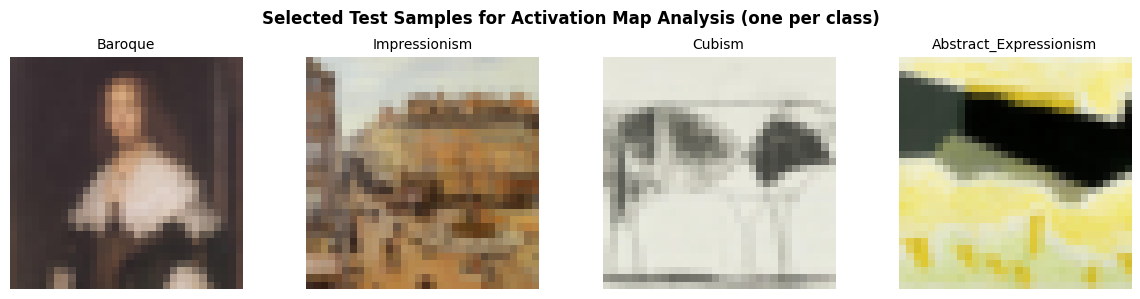

Sample images saved.


In [41]:
# ============================================================
# Section 5.1 - Select one random test image per class
# for activation map visualization
# ============================================================

np.random.seed(SEED)

# Select one sample per class from test set
sample_images = {}    # class_name → tensor [1, 3, 32, 32]
sample_labels = {}    # class_name → int label

for cls_idx, cls_name in enumerate(class_names):
    # Find all test samples of this class
    mask = (y_test == cls_idx)
    class_indices = np.where(mask)[0]

    # Pick one random sample
    chosen_idx = np.random.choice(class_indices)
    img_tensor = X_test_t[chosen_idx].unsqueeze(0)  # [1, 3, 32, 32]

    sample_images[cls_name] = img_tensor
    sample_labels[cls_name] = cls_idx

    print(f"Class '{cls_name}' (label={cls_idx}): test index {chosen_idx}, "
          f"shape {img_tensor.shape}")

# Visualize the chosen samples
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
fig.suptitle("Selected Test Samples for Activation Map Analysis (one per class)",
             fontsize=12, fontweight='bold')

for ax, cls_name in zip(axes, class_names):
    img = sample_images[cls_name][0].permute(1, 2, 0).numpy()  # [32, 32, 3]
    ax.imshow(np.clip(img, 0, 1))
    ax.set_title(cls_name, fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.savefig('section5_sample_images.png', dpi=150, bbox_inches='tight')
plt.show()
print("Sample images saved.")

Hook registered: CNN_v3_BN — ReLU at conv_layers[2] (after BatchNorm)
  Baroque: activation shape torch.Size([1, 16, 32, 32])
  Impressionism: activation shape torch.Size([1, 16, 32, 32])
  Cubism: activation shape torch.Size([1, 16, 32, 32])
  Abstract_Expressionism: activation shape torch.Size([1, 16, 32, 32])

Activation maps extracted for all classes (custom CNN).


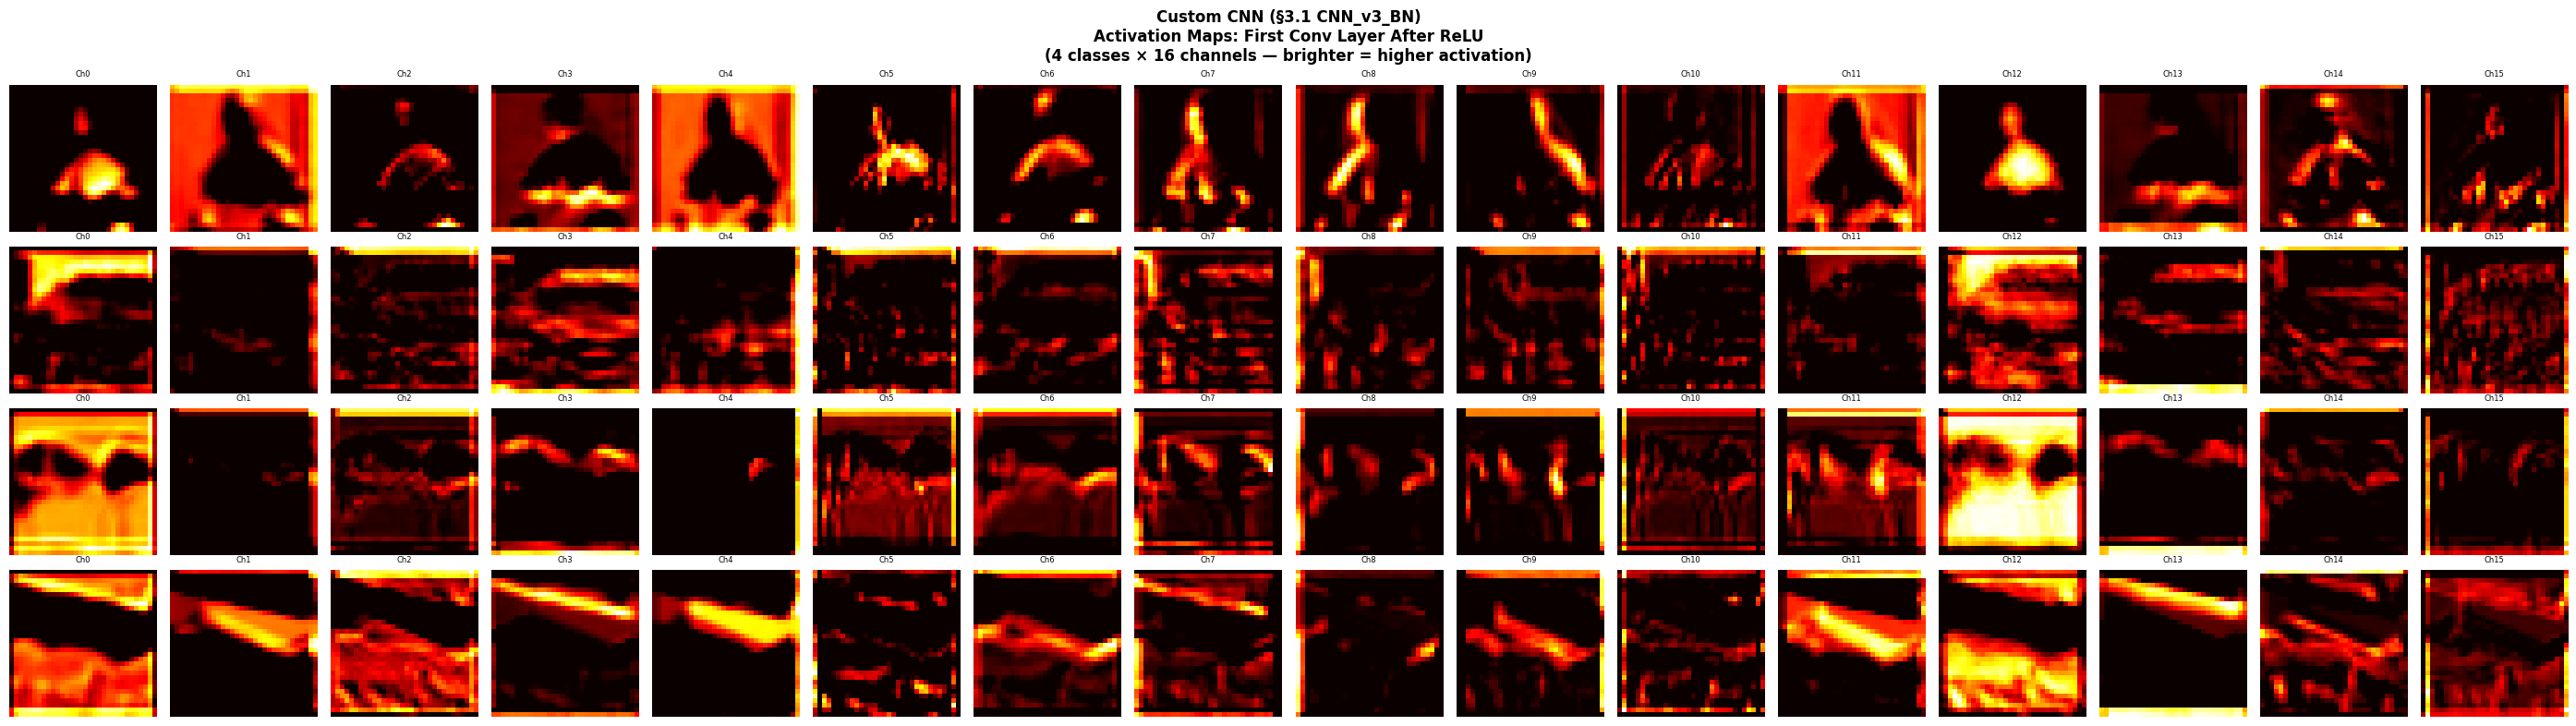

Custom CNN activation maps saved.


In [42]:
# ============================================================
# Section 5.1 - Extract activation maps from first conv layer
# Custom CNN: after first ReLU (conv_layers[0] → BN → ReLU)
#
# For CNN_v3_BN: conv_layers sequence is:
#   [0]=Conv2d  [1]=BatchNorm2d  [2]=ReLU  [3]=MaxPool2d
#   [4]=Conv2d  [5]=BatchNorm2d  [6]=ReLU  [7]=MaxPool2d ...
# For CNN_v3 (no BN):
#   [0]=Conv2d  [1]=ReLU  [2]=MaxPool2d ...
# ============================================================

eval_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# --- Determine where ReLU is in custom CNN ---
def get_cnn_activation_hook(model):
    """
    Register a forward hook on the first ReLU of the custom CNN.
    Returns: (hook_handle, activation_storage_dict)
    """
    activations = {}

    def hook_fn(module, input, output):
        activations['first_relu'] = output.detach().cpu()

    # Try CNN_v3_BN structure first: ReLU is at index 2
    # Try CNN_v3 structure: ReLU is at index 1
    try:
        # Try model_31 (CNN_v3_BN structure)
        handle = model.conv_layers[2].register_forward_hook(hook_fn)
        cnn_hook_label = "CNN_v3_BN — ReLU at conv_layers[2] (after BatchNorm)"
    except:
        handle = model.conv_layers[1].register_forward_hook(hook_fn)
        cnn_hook_label = "CNN_v3 — ReLU at conv_layers[1]"

    return handle, activations, cnn_hook_label


# Load the custom CNN model into eval mode
try:
    cnn_vis_model = model_31  # CNN_v3_BN from Section 3
    cnn_vis_model_label = "Custom CNN (§3.1 CNN_v3_BN)"
except:
    cnn_vis_model = CNN_v3()
    cnn_vis_model.load_state_dict(best_state)
    cnn_vis_model_label = "Custom CNN (CNN_v3)"

cnn_vis_model.eval()
cnn_vis_model = cnn_vis_model.to(eval_device)

# Register hook
handle_cnn, acts_cnn, cnn_hook_label = get_cnn_activation_hook(cnn_vis_model)
print(f"Hook registered: {cnn_hook_label}")

# --- Get activations for each class sample ---
cnn_activation_maps = {}  # cls_name → [1, 16, H, W]

for cls_name in class_names:
    img = sample_images[cls_name].to(eval_device)  # [1, 3, 32, 32]
    with torch.no_grad():
        _ = cnn_vis_model(img)
    cnn_activation_maps[cls_name] = acts_cnn['first_relu'].clone()  # [1, 16, H, W]
    print(f"  {cls_name}: activation shape {cnn_activation_maps[cls_name].shape}")

handle_cnn.remove()
print("\nActivation maps extracted for all classes (custom CNN).")

# --- Visualize: 4 classes × 16 channels ---
fig, axes = plt.subplots(4, 16, figsize=(28, 8))
fig.suptitle(f"{cnn_vis_model_label}\nActivation Maps: First Conv Layer After ReLU\n"
             f"(4 classes × 16 channels — brighter = higher activation)",
             fontsize=12, fontweight='bold')

for row, cls_name in enumerate(class_names):
    acts = cnn_activation_maps[cls_name][0]  # [16, H, W]
    for col in range(16):
        ax = axes[row, col]
        act_map = acts[col].numpy()          # [H, W]
        ax.imshow(act_map, cmap='hot', interpolation='nearest')
        if col == 0:
            # Short class name for y-axis label
            short_name = cls_name[:10]
            ax.set_ylabel(short_name, fontsize=8, rotation=90, va='center')
        ax.set_title(f"Ch{col}", fontsize=6)
        ax.axis('off')

plt.tight_layout()
plt.savefig('section5_cnn_activations.png', dpi=150, bbox_inches='tight')
plt.show()
print("Custom CNN activation maps saved.")

ResNet18 hook registered on model.relu (after conv1 → bn1 → relu)
ResNet18 conv1 shape: torch.Size([64, 3, 7, 7])  → [64, 3, 7, 7]
  Baroque: activation shape torch.Size([1, 64, 112, 112])
  Impressionism: activation shape torch.Size([1, 64, 112, 112])
  Cubism: activation shape torch.Size([1, 64, 112, 112])
  Abstract_Expressionism: activation shape torch.Size([1, 64, 112, 112])

Activation maps extracted for all classes (ResNet18).


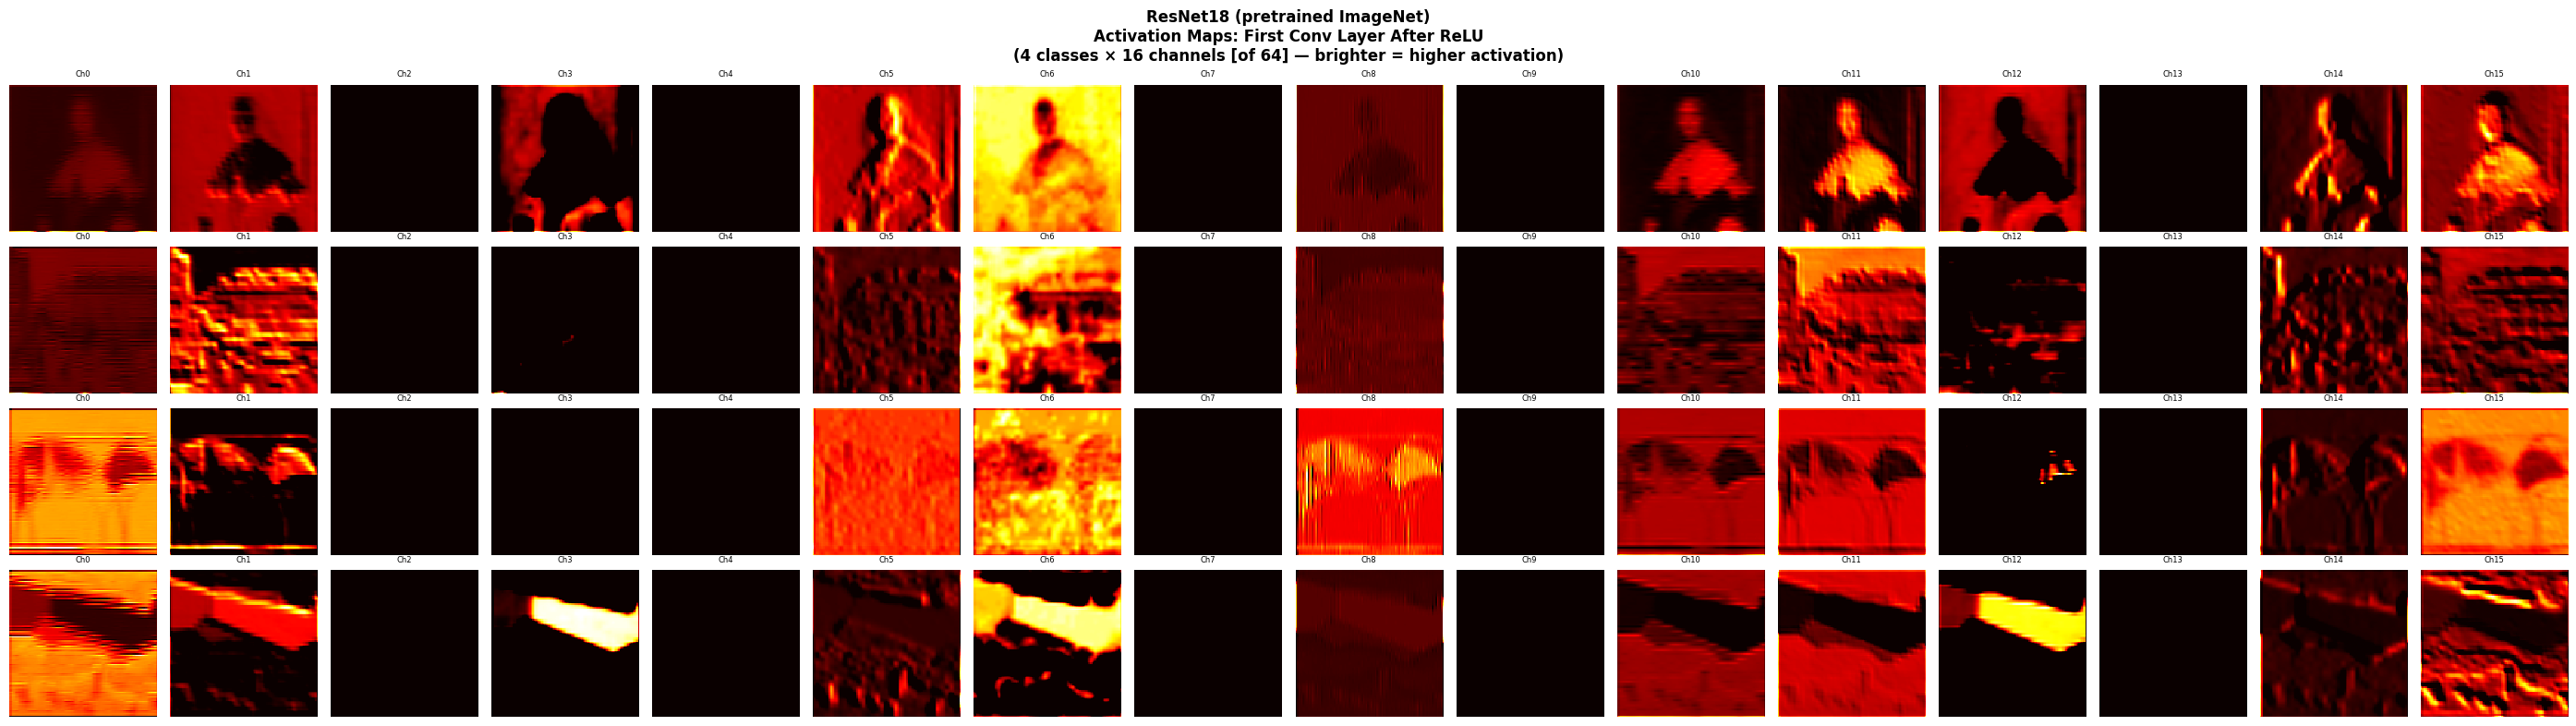

ResNet18 activation maps saved.


In [43]:
# ============================================================
# Section 5.1 - Extract activation maps from ResNet18's first conv layer
# ResNet18 architecture: conv1 → bn1 → relu
# We hook AFTER relu (model.relu)
# ============================================================

# Load the trained frozen ResNet18
resnet_vis_model = model_resnet_frozen
resnet_vis_model.eval()
resnet_vis_model = resnet_vis_model.to(eval_device)

# Register hook on the first ReLU of ResNet18 (model.relu)
acts_resnet = {}

def resnet_hook_fn(module, input, output):
    acts_resnet['first_relu'] = output.detach().cpu()

handle_resnet = resnet_vis_model.relu.register_forward_hook(resnet_hook_fn)
print("ResNet18 hook registered on model.relu (after conv1 → bn1 → relu)")
print(f"ResNet18 conv1 shape: {resnet_vis_model.conv1.weight.shape}  → [64, 3, 7, 7]")

# --- Get activations for each class (using ResNet18 preprocessed inputs) ---
resnet_activation_maps = {}  # cls_name → [1, 64, 112, 112]

for cls_name in class_names:
    img_32 = sample_images[cls_name]  # [1, 3, 32, 32]

    # Preprocess for ResNet18 (upscale + normalize)
    img_224 = torch.nn.functional.interpolate(
        img_32, size=(224, 224), mode='bilinear', align_corners=False
    )
    imagenet_mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    imagenet_std  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    img_224_norm = (img_224 - imagenet_mean) / imagenet_std
    img_224_norm = img_224_norm.to(eval_device)

    with torch.no_grad():
        _ = resnet_vis_model(img_224_norm)

    resnet_activation_maps[cls_name] = acts_resnet['first_relu'].clone()  # [1, 64, 112, 112]
    print(f"  {cls_name}: activation shape {resnet_activation_maps[cls_name].shape}")

handle_resnet.remove()
print("\nActivation maps extracted for all classes (ResNet18).")

# --- Visualize: 4 classes × 16 channels (first 16 of 64) ---
fig, axes = plt.subplots(4, 16, figsize=(28, 8))
fig.suptitle("ResNet18 (pretrained ImageNet)\nActivation Maps: First Conv Layer After ReLU\n"
             "(4 classes × 16 channels [of 64] — brighter = higher activation)",
             fontsize=12, fontweight='bold')

for row, cls_name in enumerate(class_names):
    acts = resnet_activation_maps[cls_name][0]  # [64, 112, 112] — use first 16
    for col in range(16):
        ax = axes[row, col]
        act_map = acts[col].numpy()              # [112, 112]
        ax.imshow(act_map, cmap='hot', interpolation='nearest')
        if col == 0:
            short_name = cls_name[:10]
            ax.set_ylabel(short_name, fontsize=8, rotation=90, va='center')
        ax.set_title(f"Ch{col}", fontsize=6)
        ax.axis('off')

plt.tight_layout()
plt.savefig('section5_resnet_activations.png', dpi=150, bbox_inches='tight')
plt.show()
print("ResNet18 activation maps saved.")

Recalling FFN first layer weights (from §1.1, for Q5.1 comparison)...
FFN first layer weight shape: torch.Size([128, 3072])
Reshaped to: torch.Size([128, 3, 32, 32])


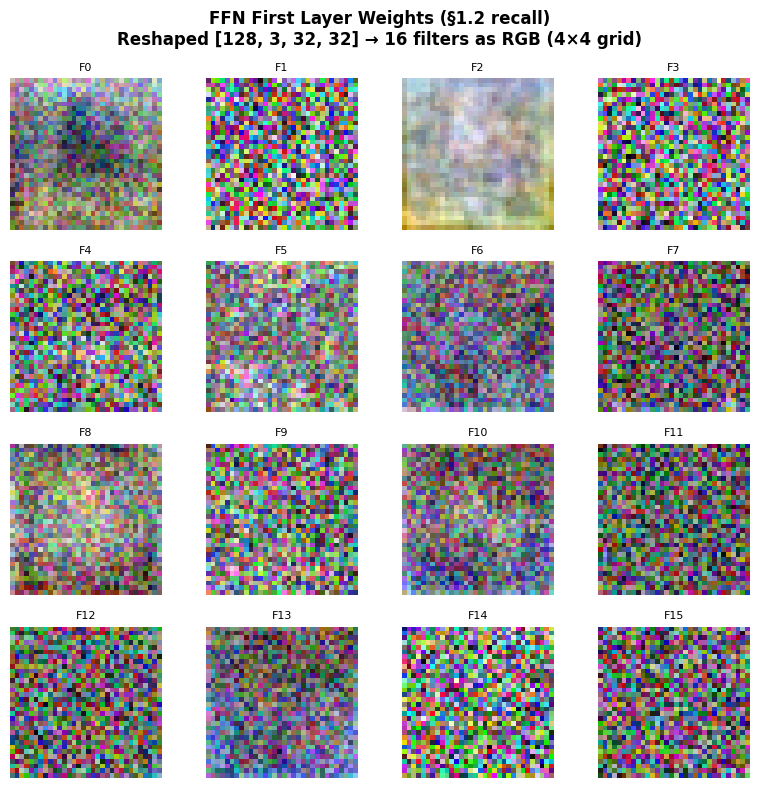

FFN weight visualization saved.


In [44]:
# ============================================================
# Section 5.1 - Recall: FFN first layer weights visualization
# from Q1.2 — reproduced here for direct comparison in Q5.1
# FFN weight shape: [128, 3072] → reshape to [128, 3, 32, 32]
# Visualize 16 filters in 4×4 grid (same as Q1.2)
# ============================================================

print("Recalling FFN first layer weights (from §1.1, for Q5.1 comparison)...")

# Extract from best_model_ffn (saved from Section 1)
# network[1] = nn.Linear(3072, 128)
ffn_first_weights = best_model_ffn.network[1].weight.data.cpu()  # [128, 3072]

print(f"FFN first layer weight shape: {ffn_first_weights.shape}")
ffn_weights_reshaped = ffn_first_weights.reshape(128, 3, 32, 32)
print(f"Reshaped to: {ffn_weights_reshaped.shape}")

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
fig.suptitle("FFN First Layer Weights (§1.2 recall)\n"
             "Reshaped [128, 3, 32, 32] → 16 filters as RGB (4×4 grid)",
             fontsize=12, fontweight='bold')

for idx, ax in enumerate(axes.flat):
    filt = ffn_weights_reshaped[idx]             # [3, 32, 32]
    filt_norm = minmax_normalize_filter(filt)              # [3, 32, 32] or None
    if filt_norm is None:
        filt_norm = torch.full_like(filt, 0.5)            # grey patch for constant filters
    img = filt_norm.permute(1, 2, 0).numpy()              # [32, 32, 3]
    ax.imshow(img, interpolation='nearest')
    ax.set_title(f"F{idx}", fontsize=8)
    ax.axis('off')

plt.tight_layout()
plt.savefig('section5_ffn_weights_recall.png', dpi=150, bbox_inches='tight')
plt.show()
print("FFN weight visualization saved.")

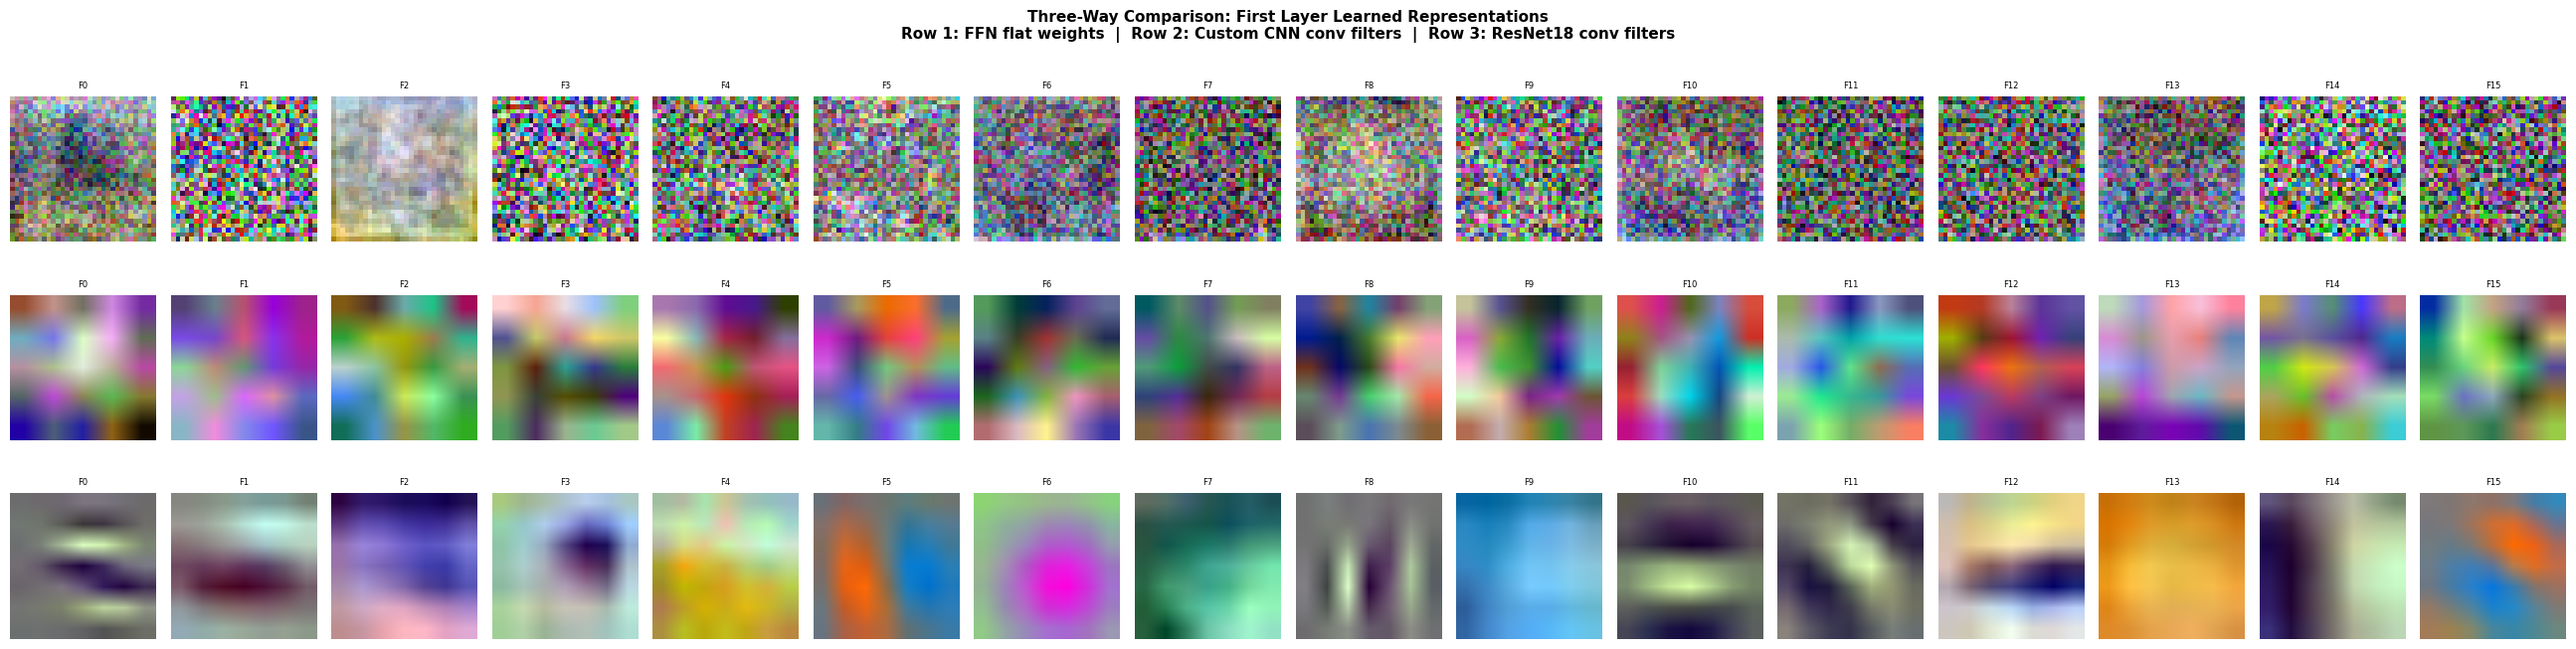

Three-way comparison saved.


In [45]:
# ============================================================
# Section 5.1 - Three-way comparison figure for Q5.1
# Row 1: FFN weights  (flat-pixel, 32×32 receptive field)
# Row 2: CNN filters  (local, 5×5 spatial)
# Row 3: ResNet18 filters (local, 7×7, ImageNet-trained)
# ============================================================

fig, axes = plt.subplots(3, 16, figsize=(26, 7))
fig.suptitle(
    "Three-Way Comparison: First Layer Learned Representations\n"
    "Row 1: FFN flat weights  |  Row 2: Custom CNN conv filters  |  Row 3: ResNet18 conv filters",
    fontsize=11, fontweight='bold'
)

all_weights = [
    (ffn_weights_reshaped,          "FFN\n(global, 32×32)"),
    (cnn_first_layer_weights,       "Custom CNN\n(local, 5×5)"),
    (resnet_first_layer_weights,    "ResNet18\n(local, 7×7)"),
]

for row, (weights, label) in enumerate(all_weights):
    for col in range(16):
        ax = axes[row, col]
        filt = weights[col]                         # [3, H, W]
        filt_norm = minmax_normalize_filter(filt)
        if filt_norm is None:
            filt_norm = torch.full_like(filt, 0.5)        # grey patch for constant filters
        img = filt_norm.permute(1, 2, 0).numpy()
        # bilinear for CNN (5×5) and ResNet18 (7×7) rows; FFN (32×32) is fine either way
        interp = 'nearest' if row == 0 else 'bilinear'
        ax.imshow(img, interpolation=interp)
        if col == 0:
            ax.set_ylabel(label, fontsize=9, rotation=90, va='center', ha='right')
        ax.set_title(f"F{col}", fontsize=6)
        ax.axis('off')

plt.tight_layout()
plt.savefig('section5_threeway_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Three-way comparison saved.")

## Q5.1 (3 μον.)

**Φίλτρα 1ου conv layer — Σύγκριση:**

- **FFN βάρη [128×3×32×32]:** Εμφανίζονται ως pixel-level θόρυβος σε σχεδόν όλα τα 16 φίλτρα — τυχαία χρώματα pixel-by-pixel χωρίς καμία χωρική δομή. Μόνο το F2 δείχνει ελαφρό ομοιόμορφο χρωματικό blob, υποδηλώνοντας ότι ελάχιστοι νευρώνες κατάφεραν να μάθουν global color bias.

- **Custom CNN [16×3×5×5]:** Αναγνωρίσιμα **color-opponent blocks** — κάθε φίλτρο αποτελείται από 2-4 μεγάλες χρωματικές περιοχές (κόκκινο vs πράσινο, κίτρινο vs μπλε, κτλ.). Δεν υπάρχουν κατευθυντικοί edge detectors, αλλά η χωρική δομή είναι εμφανής — το CNN μάθε να εντοπίζει χρωματικές αντιθέσεις σε τοπικό επίπεδο. Τα φίλτρα είναι ερμηνεύσιμα παρά τον μικρό dataset.

- **ResNet18 [64×3×7×7, πρώτα 16]:** Εμφανώς πιο λεπτομερής δομή — αναγνωρίζονται **κατευθυντικοί edge detectors** (οριζόντιες, διαγώνιες γραμμές), **color blobs** (magenta, κίτρινο-πράσινο), και **gradient patterns** (σκούρο-φωτεινό transitions). Τα 7×7 φίλτρα επιτρέπουν μεγαλύτερο receptive field. Αυτό είναι αναμενόμενο: εκπαίδευση σε 1.2M εικόνες οδηγεί σε Gabor-like patterns που αντιστοιχούν στους V1 ανιχνευτές του ανθρώπινου οπτικού συστήματος. Πέντε φίλτρα (F2, F4, F7, F9, F13) εμφανίζονται ως near-uniform patches λόγω εξαιρετικά μικρού weight range (~10⁻⁸ έως 10⁻⁶) — πιθανόν λειτουργούν ως DC detectors μέσης φωτεινότητας.

**Σύνοψη ιεραρχίας:** FFN pixel noise (global, αδόμητο) → CNN→color blocks (local, χρωματική αντίθεση) → ResNet18→edge detectors + color opponents + DC detectors (local, spatial + χρωματικό + φωτεινότητα). Η βελτίωση αντικατοπτρίζει: (α) inductive bias της locality, (β) μέγεθος dataset εκπαίδευσης.

**Activation maps — Παρατηρήσεις ανά κίνημα (βάσει των συγκεκριμένων δειγμάτων):**

- **Baroque (πορτρέτο φιγούρας):** Ισχυρή ενεργοποίηση στις ακμές σώματος/ρούχων και στα σκούρα backgrounds. Channels 0, 1 του CNN ενεργοποιούνται στο contrast φωτεινού-σκούρου — ακριβώς το chiaroscuro που αναμέναμε από το Q0.1.
- **Impressionism (αστικό τοπίο):** Πιο διάχυτη ενεργοποίηση, χωρίς σαφή εστίαση — αντικατοπτρίζει την ομοιόμορφη κατανομή χρωμάτων χωρίς σκληρές ακμές.
- **Cubism (γεωμετρικό έργο):** Ενεργοποίηση σε κάθετες/οριζόντιες ακμές — τα CNN φίλτρα ανιχνεύουν τις γεωμετρικές γραμμές. Στο ResNet18 πολλά channels παραμένουν ανενεργά (μαύρα) — εξειδίκευση σε συγκεκριμένα features. Αξιοσημείωτη εξαίρεση το Ch8 που δείχνει έντονες γραμμικές ενεργοποιήσεις ανιχνεύοντας τις γεωμετρικές δομές.
- **Abstract_Expressionism (κίτρινο-μαύρο έργο):** Ενεργοποίηση κυρίως σε μεγάλα flat color areas. Το ResNet18 ανάβει σε channels που ανιχνεύουν φωτεινά patches (κίτρινο).


**Σύγκριση με FFN βάρη (Q1.2):** Τα βάρη του FFN [128×3×32×32], ακόμα και μετά reshape, είναι εντελώς θορυβώδη και δεν περιέχουν αναγνωρίσιμα spatial patterns. Κάθε νευρώνας "βλέπει" ολόκληρη την εικόνα ταυτόχρονα (global receptive field) — αδύνατο να μάθει τοπικά features. Αντίθετα, τα conv φίλτρα (5×5 ή 7×7) λειτουργούν τοπικά, εκμεταλλεύονται το weight sharing και την shift-equivariance των visual patterns, και παράγουν ιεραρχικές αναπαραστάσεις — από απλά edges στο 1ο layer έως σύνθετα patterns στα βαθύτερα layers.